# CC3092 · Laboratorio 9 — Series de tiempo y forecasting
**Autores:** Javier López (23415) · Javier Cifuentes (23079)
**Dataset:** ElectricityLoadDiagrams20112014 (UCI) · **Objetivo:** consumo horario (kWh) por cliente, pronóstico day-ahead H=24 emitido a las 00:00.

El notebook es autocontenido: cada celda `%%writefile` crea el módulo correspondiente en `src/` o el script `run_*.py`, y las celdas de ejecución los corren.
Con `RUN_TRAINING = False` (por defecto) el notebook **carga los resultados ya calculados** en `results/`; con `True` vuelve a entrenar todo (≈1.5–2 h en CPU de 2 núcleos; mucho menos con GPU).

**Hardware de los resultados reportados:** CPU de 2 núcleos, sin GPU (el código usa CUDA automáticamente si existe).
**Restricción de cómputo:** se usan 100 clientes (mínimo permitido) elegidos con semilla 42 entre los 317 con datos completos; el mismo panel para todos los modelos.

In [1]:
import os, sys, json, glob, subprocess
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
RUN_TRAINING = False   # True = reentrenar todo
os.makedirs('src', exist_ok=True); os.makedirs('docs', exist_ok=True)
def run(cmd):
    if RUN_TRAINING:
        print(subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout[-3000:])
    else:
        print('(RUN_TRAINING=False) se usan resultados guardados para:', cmd)

## 0. Configuración y utilidades
Rutas, fechas de partición, semilla fija (42) y selección automática de dispositivo (CUDA si está disponible, si no CPU).

In [2]:
open('src/__init__.py', 'a').close()

In [3]:
%%writefile src/config.py
"""Configuración global del laboratorio (rutas, fechas de split, semillas, dispositivo)."""
from pathlib import Path
import os, random
import numpy as np

ROOT = Path(__file__).resolve().parents[1]
DATA_DIR = ROOT / "data"
RES_DIR = ROOT / "results"
FIG_DIR = RES_DIR / "figures"
MODEL_DIR = RES_DIR / "models"
PRED_DIR = RES_DIR / "predictions"
for d in (DATA_DIR, RES_DIR, FIG_DIR, MODEL_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

RAW_URL = ("https://archive.ics.uci.edu/static/public/321/"
           "electricityloaddiagrams20112014.zip")

# --- Definición del problema (PDF, sección 1) ---
PERIOD_START = "2012-01-01 00:00"
PERIOD_END = "2014-12-31 23:00"
TRAIN_END = "2014-06-30 23:00"
VAL_START, VAL_END = "2014-07-01 00:00", "2014-09-30 23:00"
TEST_START, TEST_END = "2014-10-01 00:00", "2014-12-31 23:00"
XMAS_START, XMAS_END = "2014-12-22 00:00", "2014-12-28 23:00"

L_DEFAULT = 168      # ventana de entrada (horas)
H = 24               # horizonte day-ahead
N_TEST_ORIGINS = 92  # 1-oct a 31-dic 2014
N_CLIENTS = 100      # mínimo permitido por el PDF (restricción de cómputo: CPU)
SEED = 42
MASE_M = 24          # estacionalidad usada en la escala de MASE (seasonal naive diario)


def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass


def get_device():
    import torch
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def hardware_str():
    import platform
    try:
        import torch
        if torch.cuda.is_available():
            return torch.cuda.get_device_name(0)
    except ImportError:
        pass
    return f"CPU ({os.cpu_count()} núcleos, {platform.processor() or platform.machine()})"


Overwriting src/config.py


## 1–2. Datos, exploración y preparación
Pipeline: crudo 15 min (kW) → horario (kWh) → corrección de cambios de horario → filtro de clientes completos → muestra de 100 clientes → normalización con estadísticos de entrenamiento → covariables de calendario → ventanas.

In [4]:
%%writefile src/data.py
"""Carga, limpieza y preparación del panel horario (PDF, secciones 1 y 2).

Decisiones clave
----------------
* Unidades: el archivo registra potencia media en kW de cada intervalo de 15 min.
  Energía del intervalo = kW * 0.25 h. Energía horaria (kWh) = suma de los 4 registros / 4.
* Etiquetas: verificado empíricamente con los días de cambio de horario, la marca de tiempo es
  el INICIO del intervalo (el bloque anómalo de marzo/octubre está en 01:00-01:45). Por eso se
  agrupa con floor a la hora: `ds` = inicio de la hora (01:00 = consumo de 01:00 a 02:00).
* Cambios de horario (documentación UCI): todos los días tienen 96 registros.
  - Marzo (día de 23 h): la hora 01:00-02:00 viene en cero para todos los clientes -> se
    imputa interpolando linealmente entre 00:00 y 02:00 de cada cliente.
  - Octubre (día de 25 h): la hora 01:00-02:00 acumula el consumo de dos horas -> se divide
    entre 2. Así la grilla queda regular de 24 h/día (lo que esperan los modelos).
"""
import zipfile, urllib.request
import numpy as np
import pandas as pd
from . import config as C


def download_raw():
    zpath = C.DATA_DIR / "electricity.zip"
    txt = C.DATA_DIR / "LD2011_2014.txt"
    if not txt.exists():
        if not zpath.exists():
            urllib.request.urlretrieve(C.RAW_URL, zpath)
        zipfile.ZipFile(zpath).extract("LD2011_2014.txt", C.DATA_DIR)
    return txt


def load_raw() -> pd.DataFrame:
    cache = C.DATA_DIR / "raw_15min.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    raw = pd.read_csv(download_raw(), sep=";", decimal=",", index_col=0, parse_dates=True)
    raw = raw.astype("float32")
    raw.to_parquet(cache)
    return raw


def dst_days(years=(2012, 2013, 2014)):
    """Último domingo de marzo y de octubre (regla UE) para cada año."""
    out = {}
    for y in years:
        mar = pd.Timestamp(f"{y}-03-31")
        oct_ = pd.Timestamp(f"{y}-10-31")
        out[y] = (mar - pd.Timedelta(days=(mar.weekday() + 1) % 7),
                  oct_ - pd.Timedelta(days=(oct_.weekday() + 1) % 7))
    return out


def to_hourly_kwh(raw: pd.DataFrame) -> pd.DataFrame:
    hourly = raw.resample("h").sum(min_count=4) / 4.0   # sum(kW * 0.25 h) -> kWh por hora
    return hourly.astype("float32")


def fix_dst(hourly: pd.DataFrame, log=None) -> pd.DataFrame:
    h = hourly.copy()
    for y, (mar, oct_) in dst_days().items():
        t_mar = mar + pd.Timedelta(hours=1)
        t_oct = oct_ + pd.Timedelta(hours=1)
        if t_mar in h.index:
            before = h.loc[t_mar].abs().sum()
            h.loc[t_mar] = 0.5 * (h.loc[t_mar - pd.Timedelta(hours=1)] + h.loc[t_mar + pd.Timedelta(hours=1)])
            if log is not None:
                log.append(f"{t_mar}: hora en cero (suma panel={before:.1f}) -> interpolada")
        if t_oct in h.index:
            ratio = (h.loc[t_oct].sum() / h.loc[t_oct - pd.Timedelta(hours=1)].sum())
            h.loc[t_oct] = h.loc[t_oct] / 2.0
            if log is not None:
                log.append(f"{t_oct}: hora doble (ratio vs hora previa={ratio:.2f}) -> /2")
    return h


def select_clients(hourly: pd.DataFrame):
    """Clientes con datos completos desde 2012-01-01: consumo > 0 en el primer día de 2012,
    sin NaN y sin tramos de ceros >= 7 días (series que se 'apagan')."""
    p = hourly.loc[C.PERIOD_START:C.PERIOD_END]
    first_day_ok = p.loc[:"2012-01-01 23:00"].sum() > 0
    no_nan = p.notna().all()
    daily = p.resample("D").sum()
    zero_days = (daily == 0)
    # racha máxima de días en cero por cliente
    def max_run(col):
        s = col.values.astype(int)
        best = cur = 0
        for v in s:
            cur = cur + 1 if v else 0
            best = max(best, cur)
        return best
    runs = zero_days.apply(max_run)
    keep = first_day_ok & no_nan & (runs < 7)
    summary = pd.DataFrame({"first_day_ok": first_day_ok, "no_nan": no_nan,
                            "max_zero_run_days": runs, "keep": keep})
    return p.loc[:, keep], summary


def sample_clients(panel: pd.DataFrame, n=C.N_CLIENTS, seed=C.SEED):
    rng = np.random.default_rng(seed)
    cols = sorted(rng.choice(panel.columns.values, size=min(n, panel.shape[1]), replace=False))
    return panel[cols]


def pt_holidays(index: pd.DatetimeIndex) -> pd.Series:
    import holidays
    pt = holidays.Portugal(years=sorted(set(index.year)))
    return pd.Series([d.date() in pt for d in index], index=index, dtype="int8"), pt


def calendar_features(index: pd.DatetimeIndex) -> pd.DataFrame:
    """Covariables conocidas a futuro, codificadas con seno/coseno (continuidad circular:
    23h está cerca de 0h) + indicadores de feriado y fin de semana."""
    hol, _ = pt_holidays(index)
    hour, dow, month = index.hour.values, index.dayofweek.values, index.month.values - 1
    df = pd.DataFrame({
        "hour_sin": np.sin(2 * np.pi * hour / 24), "hour_cos": np.cos(2 * np.pi * hour / 24),
        "dow_sin": np.sin(2 * np.pi * dow / 7), "dow_cos": np.cos(2 * np.pi * dow / 7),
        "month_sin": np.sin(2 * np.pi * month / 12), "month_cos": np.cos(2 * np.pi * month / 12),
        "is_holiday": hol.values.astype(np.float32),
        "is_weekend": (dow >= 5).astype(np.float32),
    }, index=index).astype("float32")
    return df


def build_panel(n_clients=C.N_CLIENTS, seed=C.SEED, verbose=True):
    """Pipeline completo crudo -> panel horario limpio. Devuelve (panel_sel, info)."""
    cache = C.DATA_DIR / f"panel_{n_clients}_{seed}.parquet"
    info = {}
    if cache.exists() and (C.DATA_DIR / "panel_all.parquet").exists():
        panel_sel = pd.read_parquet(cache)
        info["panel_all"] = pd.read_parquet(C.DATA_DIR / "panel_all.parquet")
        info["selection"] = pd.read_csv(C.DATA_DIR / "client_selection.csv", index_col=0)
        info["dst_log"] = (C.DATA_DIR / "dst_log.txt").read_text().splitlines()
        return panel_sel, info
    raw = load_raw()
    info["raw_shape"] = raw.shape
    hourly = to_hourly_kwh(raw)
    log = []
    hourly = fix_dst(hourly, log)
    panel_all, summary = select_clients(hourly)
    panel_sel = sample_clients(panel_all, n_clients, seed)
    panel_all.to_parquet(C.DATA_DIR / "panel_all.parquet")
    panel_sel.to_parquet(cache)
    summary.to_csv(C.DATA_DIR / "client_selection.csv")
    (C.DATA_DIR / "dst_log.txt").write_text("\n".join(log))
    info.update(panel_all=panel_all, selection=summary, dst_log=log)
    return panel_sel, info


def split_index(index: pd.DatetimeIndex):
    """Índices enteros (posiciones) de inicio de cada partición en la grilla horaria."""
    pos = {k: index.get_loc(pd.Timestamp(v)) for k, v in
           dict(val=C.VAL_START, test=C.TEST_START).items()}
    return pos["val"], pos["test"]


class Scaler:
    """z-score por serie con estadísticos SOLO del bloque de entrenamiento (fuga #2)."""
    def __init__(self, mode="series"):
        assert mode in ("series", "global", "none")
        self.mode = mode

    def fit(self, Y_train: np.ndarray):  # (n_series, T_train)
        if self.mode == "series":
            self.mu = Y_train.mean(1, keepdims=True)
            self.sd = Y_train.std(1, keepdims=True) + 1e-6
        elif self.mode == "global":
            self.mu = np.full((Y_train.shape[0], 1), Y_train.mean())
            self.sd = np.full((Y_train.shape[0], 1), Y_train.std() + 1e-6)
        else:
            self.mu = np.zeros((Y_train.shape[0], 1)); self.sd = np.ones((Y_train.shape[0], 1))
        self.mu, self.sd = self.mu.astype(np.float32), self.sd.astype(np.float32)
        return self

    def transform(self, Y, idx=None):
        mu, sd = (self.mu, self.sd) if idx is None else (self.mu[idx], self.sd[idx])
        return (Y - mu) / sd

    def inverse(self, Z, idx=None):
        mu, sd = (self.mu, self.sd) if idx is None else (self.mu[idx], self.sd[idx])
        return Z * sd + mu


def to_long(panel: pd.DataFrame) -> pd.DataFrame:
    """Formato Nixtla (unique_id, ds, y)."""
    df = panel.copy(); df.index.name = "ds"
    return df.reset_index().melt(id_vars="ds", var_name="unique_id", value_name="y")[["unique_id", "ds", "y"]]


Overwriting src/data.py


In [5]:
%%writefile src/prep.py
"""Atajo para construir el contexto común (mismo panel de clientes para TODOS los modelos)."""
import numpy as np
import pandas as pd
from . import config as C, data as D
from .backtest import Context
from .metrics import mase_scale


def get_context(n_clients=C.N_CLIENTS, seed=C.SEED):
    panel, _ = D.build_panel(n_clients, seed)
    dates = panel.index
    cal_df = D.calendar_features(dates)
    val_pos, test_pos = D.split_index(dates)
    Y = panel.values.T.astype(np.float32)               # (n_series, T)
    scale = mase_scale(Y[:, :val_pos], C.MASE_M)          # escala MASE: solo entrenamiento
    ctx = Context(Y, dates, cal_df.values, np.array(panel.columns), scale, val_pos, test_pos)
    ctx.cal_cols = list(cal_df.columns)
    ctx.panel = panel
    return ctx


Overwriting src/prep.py


### Dataset de ventanas deslizantes (L=168, H=24, stride=1)

In [6]:
%%writefile src/windows.py
"""Dataset de ventanas deslizantes (PDF sección 2).

Convención: `t` = índice del ORIGEN = primera hora a pronosticar.
  entrada  X  = posiciones [t-L, t)    -> (L, 1 + n_cal): [y_norm, calendario de esas horas]
  futuro   XF = posiciones [t, t+H)    -> (H, n_cal): calendario conocido a futuro
  objetivo y  = posiciones [t, t+H)    -> (H,)
Una ventana pertenece a la partición en la que cae su OBJETIVO completo; la entrada puede venir
de la partición anterior porque esa historia ya es conocida en el instante t (no es fuga).
"""
import numpy as np
import torch
from torch.utils.data import Dataset


def origin_range(T, L, H, t_lo, t_hi):
    """Orígenes válidos t con objetivo dentro de [t_lo, t_hi) y entrada dentro de [0, t)."""
    first = max(t_lo, L)
    last = t_hi - H  # inclusive
    return first, last


class WindowDataset(Dataset):
    def __init__(self, Yn, cal, L, H, t_lo, t_hi, stride=1, series=None, hist_lo=0):
        """Yn: (n_series, T) normalizado; cal: (T, n_cal).
        hist_lo: primera posición permitida para la ENTRADA (para limitar meses de historia)."""
        self.Yn = torch.as_tensor(Yn, dtype=torch.float32)
        self.cal = torch.as_tensor(cal, dtype=torch.float32)
        self.L, self.H = L, H
        first, last = origin_range(Yn.shape[1], L, H, max(t_lo, hist_lo + L), t_hi)
        self.origins = np.arange(first, last + 1, stride)
        self.series = np.arange(Yn.shape[0]) if series is None else np.asarray(series)
        self.n_o = len(self.origins)

    def __len__(self):
        return len(self.series) * self.n_o

    def __getitem__(self, i):
        s = self.series[i // self.n_o]
        t = int(self.origins[i % self.n_o])
        L, H = self.L, self.H
        x = torch.cat([self.Yn[s, t - L:t, None], self.cal[t - L:t]], dim=1)
        return x, self.cal[t:t + H], self.Yn[s, t:t + H], s

    def target_positions(self):
        """Posiciones mínima y máxima que tocan los objetivos (para la auditoría de fugas)."""
        return int(self.origins.min()), int(self.origins.max() + self.H - 1)


Overwriting src/windows.py


### Exploración, conteo de ventanas y auditoría de fugas
El script contiene `assert`s: si alguna fuga existiera, la celda fallaría.

In [7]:
%%writefile run_00_eda.py
"""Sección 2: exploración, conteo de ventanas y auditoría de las 4 fugas (con asserts)."""
import json
import numpy as np, pandas as pd, torch
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from src import config as C, data as D
from src.prep import get_context
from src.windows import WindowDataset
from src.data import Scaler

ctx = get_context()
panel_all = pd.read_parquet(C.DATA_DIR / "panel_all.parquet")
panel = ctx.panel
out = {}
# ---------- escalas ----------
means_all = panel_all.loc[:C.TRAIN_END].mean()
means_sel = panel.loc[:C.TRAIN_END].mean()
out["scale_all"] = means_all.describe()[["min", "50%", "max"]].round(3).to_dict()
out["scale_sel"] = means_sel.describe()[["min", "50%", "max"]].round(3).to_dict()
out["n_clients_filter"], out["n_clients_used"] = panel_all.shape[1], panel.shape[1]
out["hours_per_series"] = panel.shape[0]
out["obs_panel_used"], out["obs_panel_filtered"] = int(panel.size), int(panel_all.size)

# ---------- perfiles (consumo normalizado por la media de cada cliente) ----------
rel = panel / panel.loc[:C.TRAIN_END].mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
prof_h = rel.groupby(rel.index.hour).mean().mean(1)
prof_d = rel.groupby(rel.index.dayofweek).mean().mean(1)
hm = rel.mean(1).groupby([rel.index.dayofweek, rel.index.hour]).mean().unstack()
ax[0].plot(prof_h.index, prof_h.values, marker="o"); ax[0].set(title="Perfil por hora del día", xlabel="hora", ylabel="consumo / media del cliente")
ax[1].bar(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], prof_d.values); ax[1].set(title="Perfil por día de la semana")
im = ax[2].imshow(hm.values, aspect="auto", cmap="viridis"); ax[2].set(title="Día de semana × hora", xlabel="hora", yticks=range(7), yticklabels=["L", "M", "X", "J", "V", "S", "D"])
plt.colorbar(im, ax=ax[2]); plt.tight_layout(); plt.savefig(C.FIG_DIR / "perfiles.png", dpi=130); plt.close()

# ---------- serie diaria con feriados ----------
hol, pt = D.pt_holidays(panel.index)
daily = rel.mean(1).resample("D").mean()
hol_days = sorted({d for d in pd.to_datetime(list(pt.keys())) if daily.index[0] <= d <= daily.index[-1]})
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(daily.index, daily.values, lw=0.8)
ax.scatter(hol_days, daily.reindex(hol_days).values, color="red", s=18, zorder=3, label="feriado PT")
for a, b, c in [(C.VAL_START, C.VAL_END, "orange"), (C.TEST_START, C.TEST_END, "green")]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), alpha=0.12, color=c)
ax.set(title="Consumo diario relativo del panel (rojo: feriados de Portugal; naranja=val, verde=test)"); ax.legend()
plt.tight_layout(); plt.savefig(C.FIG_DIR / "serie_diaria_feriados.png", dpi=130); plt.close()
out["holidays"] = {str(k): v for k, v in sorted(pt.items())}

# ---------- Navidad y Año Nuevo ----------
fig, ax = plt.subplots(figsize=(12, 4)); xmas = {}
for y in (2012, 2013, 2014):
    s = daily.loc[f"{y}-12-15":f"{y}-12-31"]
    if y < 2014: s = pd.concat([s, daily.loc[f"{y+1}-01-01":f"{y+1}-01-07"]])
    ax.plot(range(len(s)), s.values, marker=".", label=str(y))
    base = daily.loc[f"{y}-11-17":f"{y}-12-14"]
    for d in ("12-24", "12-25", "12-31"):
        day = pd.Timestamp(f"{y}-{d}")
        same_dow = base[base.index.dayofweek == day.dayofweek].mean()
        xmas[f"{y}-{d}"] = round(float(daily[day] / same_dow), 3)
    if y < 2014:
        day = pd.Timestamp(f"{y+1}-01-01"); same_dow = base[base.index.dayofweek == day.dayofweek].mean()
        xmas[f"{y+1}-01-01"] = round(float(daily[day] / same_dow), 3)
ax.set(title="15-dic a 7-ene: consumo diario relativo", xlabel="días desde 15-dic"); ax.legend()
plt.tight_layout(); plt.savefig(C.FIG_DIR / "navidad.png", dpi=130); plt.close()
out["xmas_ratio_vs_same_weekday_prev4w"] = xmas

# ---------- escalas (histograma) ----------
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(means_all + 1e-3), bins=40, alpha=0.6, label="317 filtrados")
ax.hist(np.log10(means_sel + 1e-3), bins=40, alpha=0.6, label="100 usados")
ax.set(xlabel="log10(consumo medio horario, kWh)", title="Escalas entre clientes"); ax.legend()
plt.tight_layout(); plt.savefig(C.FIG_DIR / "escalas.png", dpi=130); plt.close()

# ---------- conteo de ventanas ----------
sc = Scaler("series").fit(ctx.Y[:, :ctx.val_pos]); Yn = sc.transform(ctx.Y)
L, H = 168, 24
dtr = WindowDataset(Yn, ctx.cal, L, H, 0, ctx.val_pos)
dva = WindowDataset(Yn, ctx.cal, L, H, ctx.val_pos, ctx.test_pos)
dte = WindowDataset(Yn, ctx.cal, L, H, ctx.test_pos, ctx.T)
out["windows"] = {k: dict(per_series=d.n_o, panel=len(d)) for k, d in
                  [("train", dtr), ("val", dva), ("test", dte)]}
out["windows"]["test_daily_origins"] = len(ctx.origins("test"))
out["windows"]["val_daily_origins"] = len(ctx.origins("val"))
x, xf, y, s = dtr[0]
out["tensor_shapes"] = dict(x=list(x.shape), xf=list(xf.shape), y=list(y.shape))

# ---------- AUDITORÍA DE FUGAS ----------
audit = []
# (1) Split aleatorio de ventanas: los splits son por tiempo y los objetivos no se traslapan.
tr_lo, tr_hi = dtr.target_positions(); va_lo, va_hi = dva.target_positions(); te_lo, te_hi = dte.target_positions()
assert tr_hi < ctx.val_pos <= va_lo and va_hi < ctx.test_pos <= te_lo
audit.append(f"1) Split temporal: objetivos train hasta {ctx.dates[tr_hi]}, val {ctx.dates[va_lo]}..{ctx.dates[va_hi]}, "
             f"test desde {ctx.dates[te_lo]}. Ningún objetivo cruza de bloque. El muestreo aleatorio (shuffle) "
             f"ocurre SOLO dentro de las ventanas de entrenamiento.")
# (2) Escalado con toda la serie: estadísticos solo de train y verificación de que difieren de los globales.
mu_full = ctx.Y.mean(1, keepdims=True)
assert np.allclose(sc.mu, ctx.Y[:, :ctx.val_pos].mean(1, keepdims=True))
Y_pert = ctx.Y.copy(); Y_pert[:, ctx.val_pos:] *= 10       # alterar el futuro no cambia el scaler
assert np.allclose(Scaler("series").fit(Y_pert[:, :ctx.val_pos]).mu, sc.mu)
audit.append(f"2) Escalado: mu/sd por serie calculados con Y[:, :val_pos] (hasta {C.TRAIN_END}). "
             f"Multiplicar val+test por 10 no cambia los estadísticos. Diferencia media |mu_train - mu_full| = "
             f"{float(np.abs(sc.mu - mu_full).mean()):.2f} kWh (lo que se habría filtrado).")
# (3) Early stopping con prueba: el trainer solo recibe orígenes de validación.
vo = ctx.origins("val")
assert ctx.dates[vo.max() + 23] < pd.Timestamp(C.TEST_START)
audit.append(f"3) Early stopping: train_model() evalúa en {len(vo)} orígenes de validación, último objetivo "
             f"{ctx.dates[vo.max()+23]} < {C.TEST_START}. La prueba solo se toca en backtest(split='test') tras entrenar.")
# (4) Covariables mal alineadas: el calendario futuro corresponde exactamente a las horas objetivo,
#     y la entrada de la red no cambia si se altera el futuro (test de perturbación).
t = int(dte.origins[0])
x1, xf1, y1, _ = dte[0]
assert torch.allclose(xf1, torch.as_tensor(D.calendar_features(ctx.dates[t:t + H]).values))
Yn2 = Yn.copy(); Yn2[:, t:] = 999.0
x2, _, _, _ = WindowDataset(Yn2, ctx.cal, L, H, ctx.test_pos, ctx.T)[0]
assert torch.equal(x1, x2), "la entrada depende del futuro!"
from src.lgbm import make_rows
Xa, _ = make_rows(Yn, ctx.cal, t, t + 1, series=[0]); Xb, _ = make_rows(Yn2, ctx.cal, t, t + 1, series=[0])
assert np.array_equal(Xa, Xb)
audit.append("4) Alineación: XF = calendario de [t, t+H) (determinístico, conocido a futuro); la entrada X usa "
             "[t-L, t). Poner y[t:] = 999 no altera X (ni las filas de rezagos de LightGBM): toda entrada es "
             "calculable a las 00:00 del día pronosticado con datos hasta las 23:00 del día previo.")
audit.append("Extra) backtest() pasa Y[:, :o] al modelo; para librerías se verifica que cutoff == o-1.")
out["leakage_audit"] = audit
json.dump(out, open(C.RES_DIR / "eda_summary.json", "w"), indent=1, default=str)
print(json.dumps({k: v for k, v in out.items() if k != "holidays"}, indent=1, default=str))


Overwriting run_00_eda.py


In [8]:
%run run_00_eda.py

{
 "scale_all": {
  "min": 4.331,
  "50%": 148.133,
  "max": 48817.773
 },
 "scale_sel": {
  "min": 8.282,
  "50%": 153.511,
  "max": 11479.638
 },
 "n_clients_filter": 317,
 "n_clients_used": 100,
 "hours_per_series": 26304,
 "obs_panel_used": 2630400,
 "obs_panel_filtered": 8338368,
 "xmas_ratio_vs_same_weekday_prev4w": {
  "2012-12-24": 0.961,
  "2012-12-25": 0.741,
  "2012-12-31": 0.997,
  "2013-01-01": 0.77,
  "2013-12-24": 0.984,
  "2013-12-25": 0.76,
  "2013-12-31": 1.017,
  "2014-01-01": 0.781,
  "2014-12-24": 0.978,
  "2014-12-25": 0.671,
  "2014-12-31": 0.966
 },
 "windows": {
  "train": {
   "per_series": 21697,
   "panel": 2169700
  },
  "val": {
   "per_series": 2185,
   "panel": 218500
  },
  "test": {
   "per_series": 2185,
   "panel": 218500
  },
  "test_daily_origins": 92,
  "val_daily_origins": 92
 },
 "tensor_shapes": {
  "x": [
   168,
   9
  ],
  "xf": [
   24,
   8
  ],
  "y": [
   24
  ]
 },
 "leakage_audit": [
  "1) Split temporal: objetivos train hasta 2014-06-

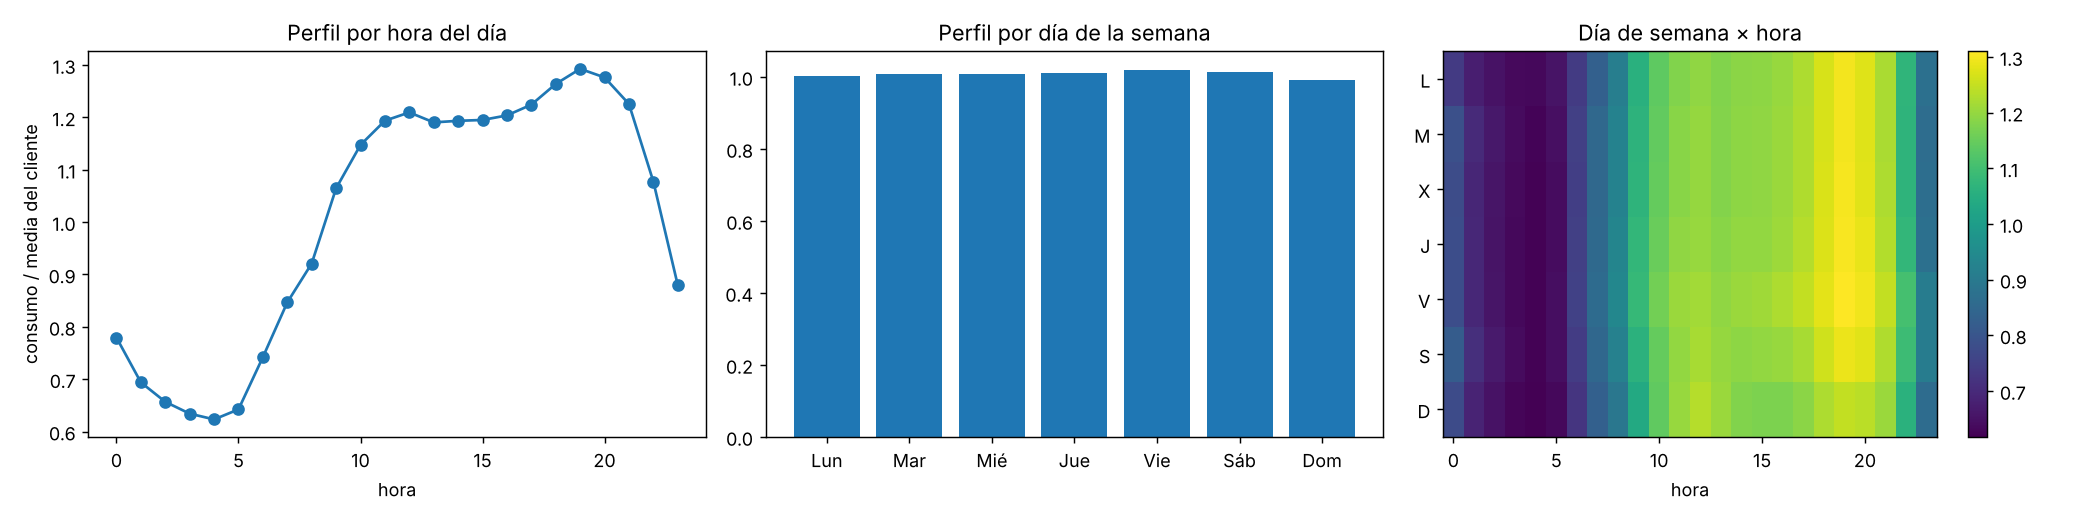

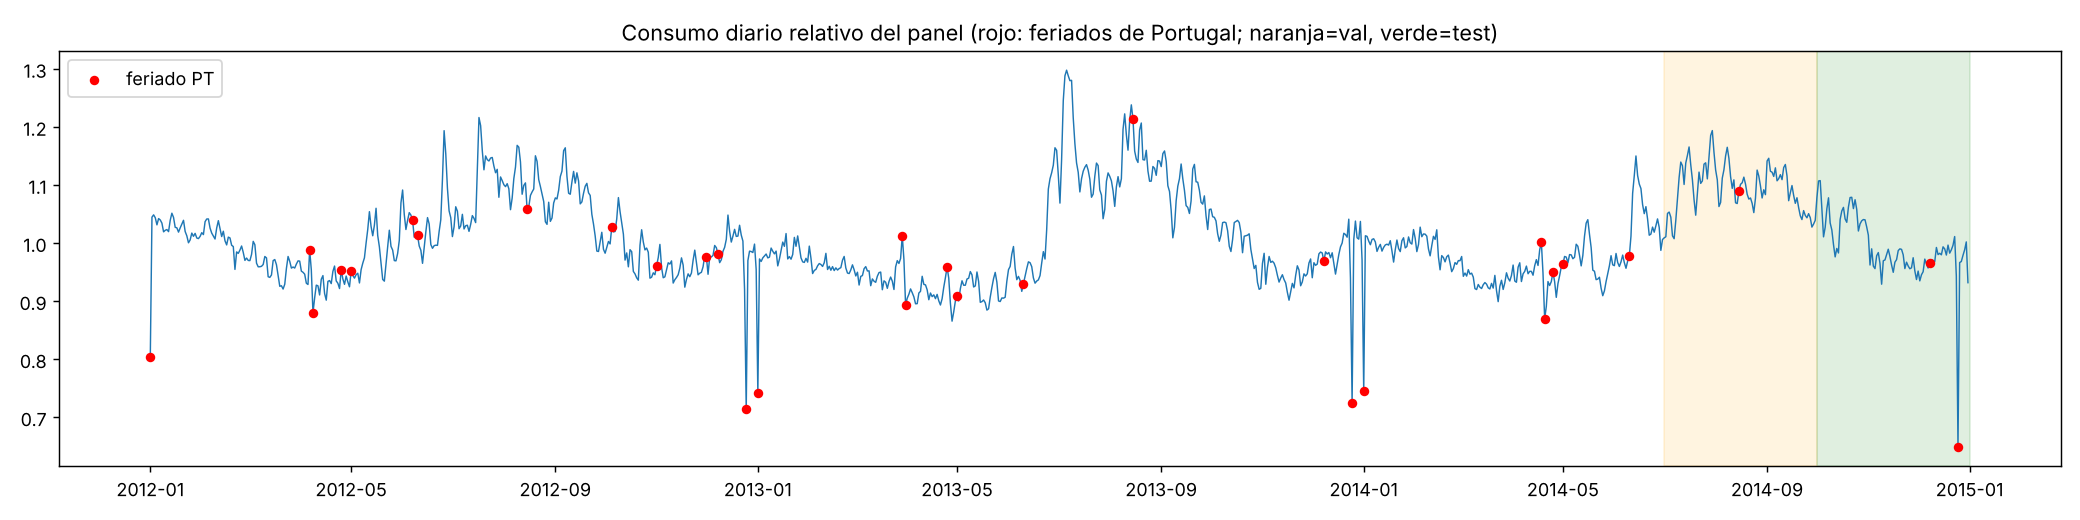

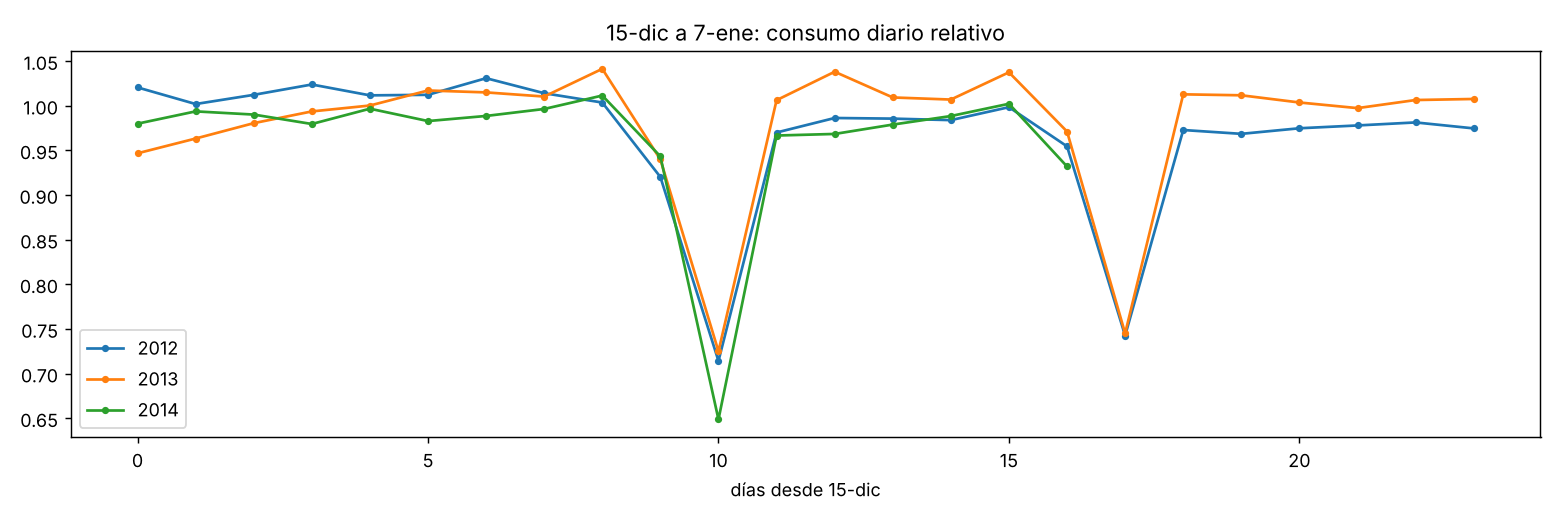

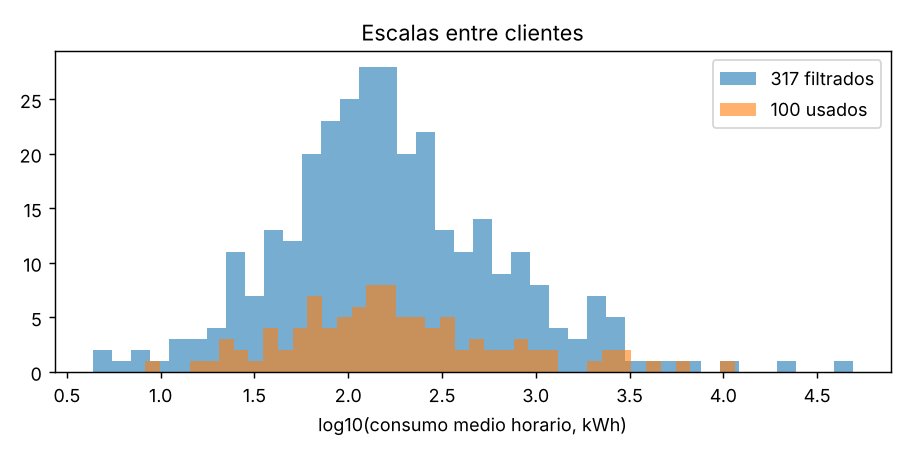

In [9]:
for f in ['perfiles','serie_diaria_feriados','navidad','escalas']: display(Image(f'results/figures/{f}.png'))

### Respuestas — sección 2 (valores calculados por `run_00_eda.py`)

**Unidades.** Cada registro es la potencia media (kW) de un intervalo de 15 min, así que su energía es kW × 0.25 h. El consumo horario es `kWh = (x₁+x₂+x₃+x₄)/4`. Al revisar los días de cambio de horario se confirmó que la marca de tiempo corresponde al **inicio** del intervalo (el bloque anómalo de marzo y octubre está en 01:00–01:45), por lo que se agrupa con `floor` a la hora.

**Clientes y observaciones.** El archivo crudo tiene 140,256 × 370 registros. Quedan **317 clientes** con datos completos desde 2012-01-01: tienen consumo > 0 el primer día, no tienen NaN y ningún tramo de ceros ≥ 7 días (53 se excluyen porque empiezan tarde o se apagan). Cada serie tiene **26,304 horas** (1,096 días × 24) y el panel filtrado suma **8,338,368** observaciones. Por restricción de cómputo (CPU de 2 núcleos, sin GPU) se usan **100 clientes** elegidos con `numpy.random.default_rng(42)` (2,630,400 observaciones), los mismos para todos los modelos.

**Cambios de horario.** Todos los días tienen 96 registros. En marzo (día de 23 h) la hora 01:00 viene en cero: la suma del panel en esa hora es ~4.3k kWh, contra ~120k en las horas vecinas. Se imputa con la media de 00:00 y 02:00 de cada cliente. En octubre (día de 25 h) la hora 01:00 acumula dos horas: su proporción frente a la hora previa es de 1.54 a 1.70, cuando lo normal es menos de 1, así que se divide entre 2. Así la grilla queda regular, con 24 h/día y sin huecos.

**Perfiles y feriados.** El consumo relativo mínimo es de 0.62× la media hacia las 04:00 y el máximo de 1.29× a las 19–20 h. Hay una meseta de 11 a 17 h. La diferencia entre días de la semana es pequeña en el promedio normalizado (domingo ≈ 0.99, viernes ≈ 1.02) porque el panel mezcla perfiles comerciales y residenciales. Los feriados se obtienen con `holidays.Portugal`, que respeta la suspensión de Corpo de Deus, 5-oct, 1-nov y 1-dic en 2013–2014.

**Navidad y Año Nuevo.** Frente al mismo día de la semana de las 4 semanas previas, el 25-dic cae a 0.74 (2012), 0.76 (2013) y **0.67 (2014, en prueba)**. El 1-ene cae a 0.77–0.78. En cambio, el 24-dic (0.96–0.98) y el 31-dic (0.97–1.02) casi no cambian. Es un cambio de régimen corto y fuerte, concentrado en los días feriados.

**Escalas.** El consumo medio horario en entrenamiento va de **4.3 a 48,818 kWh** (mediana 148) en los 317 clientes, y de **8.3 a 11,480 kWh** (mediana 154) en los 100 usados: más de 3 órdenes de magnitud. Se elige **z-score por serie con media y desviación del bloque de entrenamiento**. Una normalización global haría que los clientes grandes dominaran la pérdida, y una por ventana (RevIN) pierde la información de nivel. Ambas alternativas se comparan en las iteraciones (sección 5.2).

**Covariables de calendario conocidas a futuro.** Son la hora (seno/coseno, periodo 24), el día de la semana (seno/coseno, periodo 7), el mes (seno/coseno, periodo 12), `is_holiday` y `is_weekend`: 8 en total. Seno/coseno conserva la continuidad circular (23 h está junto a 0 h) con 2 columnas en vez de 24 one-hot. Como son funciones deterministas de la fecha, se conocen en el instante del pronóstico.

**Ventanas (L=168, H=24, stride=1).** Una ventana pertenece a la partición donde cae su objetivo completo. La entrada puede usar la historia del bloque anterior, que ya es conocida en el origen.

| partición | ventanas por serie | ventanas del panel (100 series) |
|---|---|---|
| entrenamiento | 21,697 | 2,169,700 |
| validación | 2,185 | 218,500 |
| prueba | 2,185 | 218,500 (backtest: 92 orígenes diarios × 100) |

Los tensores tienen forma `X: (batch, 168, 9)` (y normalizada + 8 covariables), `X_fut: (batch, 24, 8)` y `y: (batch, 24)`. Por costo de CPU, cada epoch muestrea con reemplazo un subconjunto fijo de ventanas de entrenamiento (`RandomSampler(num_samples)`).

**Auditoría de fugas** (todas verificadas con `assert`):
1. *Split aleatorio de ventanas:* las particiones son temporales. Los objetivos de entrenamiento terminan el 2014-06-30 23:00, los de validación cubren del 2014-07-01 al 2014-09-30 y los de prueba empiezan el 2014-10-01. Solo se barajan ventanas dentro de entrenamiento.
2. *Escalar con toda la serie:* μ y σ salen de `Y[:, :val_pos]`. Multiplicar validación y prueba por 10 no cambia el scaler. Usar la serie completa habría desplazado μ en 5.17 kWh en promedio.
3. *Early stopping con la prueba:* `train_model` solo evalúa en los 92 orígenes de validación (último objetivo: 2014-09-30 23:00). La prueba se usa una sola vez, en `backtest(split='test')`.
4. *Covariables mal alineadas:* `X_fut` es exactamente el calendario de `[t, t+H)`. Poner `y[t:] = 999` no altera la entrada `X` ni las filas de rezagos de LightGBM. Además, `backtest()` entrega `Y[:, :o]` a cada modelo, y en las librerías se verifica `cutoff == o − 1`.


## 3. Investigación: herramientas para forecasting en PyTorch

**`nn.LSTM` / `nn.GRU`.** Redes recurrentes con compuertas que procesan la secuencia paso a paso y mantienen un estado oculto (y, en LSTM, una celda de memoria `c`) para capturar dependencias largas. Parámetros: `input_size` (número de features por paso; aquí 1 + 8 covariables = 9), `hidden_size` (dimensión del estado), `num_layers` (capas apiladas), `batch_first=True` (tensores `(batch, seq, feature)`), `dropout` (entre capas; solo si `num_layers>1`). Salidas: `output` `(B, L, D·hidden)` con el estado de la última capa en cada paso; `h_n` `(D·num_layers, B, hidden)` con el último estado de cada capa; `c_n` (solo LSTM) con la última celda. La GRU fusiona compuertas y no tiene `c_n` (menos parámetros). En forecasting, `output[:, -1]` o `h_n[-1]` resume la historia para una cabeza densa (multi-salida) o inicializa un decoder (seq2seq).

**`nn.Conv1d` con dilatación y padding causal.** Convolución 1D sobre `(B, C_in, L)`; parámetros `in_channels`, `out_channels`, `kernel_size` k, `dilation` d, `padding`. Para que la salida en t solo dependa de entradas ≤ t se rellena **solo a la izquierda** con `(k−1)·d` ceros (o `padding=(k−1)·d` y se recortan los últimos elementos). Con dilataciones crecientes `d_i = 2^i`, el campo receptivo de una TCN con `n` capas (una conv por capa) es `R = 1 + (k−1)·Σ d_i = 1 + (k−1)(2^n − 1)`; con dos convoluciones por bloque residual se multiplica el término por 2. Ej.: k=2, 8 capas → R = 256 ≥ L=168.

**`nn.TransformerEncoderLayer`.** Bloque de auto-atención multi-cabeza + red feed-forward con residuales y LayerNorm. Parámetros: `d_model` (dimensión de los tokens), `nhead` (cabezas; `d_model` debe ser divisible), `dim_feedforward` (ancho de la FFN), `dropout`, `batch_first`. La atención es invariante a permutaciones, por lo que se suma una **codificación posicional** a los embeddings: sinusoidal fija `PE(pos,2i)=sin(pos/10000^{2i/d})`, `PE(pos,2i+1)=cos(·)`, o aprendida (`nn.Parameter` de `(L, d_model)`). PatchTST tokeniza la serie en parches (p. ej. 24 h) y añade posiciones aprendidas; iTransformer invierte el eje: cada **serie** es un token y la atención modela relaciones entre variables.

**NeuralForecast y StatsForecast (Nixtla).** Formato largo: `unique_id` (serie), `ds` (fecha) y `y` (objetivo), más columnas de covariables (`futr_exog_list`, `hist_exog_list`). `StatsForecast(models, freq, n_jobs)` ajusta modelos locales (uno por serie); `NeuralForecast(models, freq)` entrena modelos globales. `cross_validation(df, n_windows, step_size, refit, ...)` hace backtesting con origen móvil: `n_windows` = número de orígenes (aquí 92), `step_size` = avance entre orígenes (24 h), `h` = horizonte; `refit=False` entrena una sola vez y reutiliza los pesos para todos los orígenes (lo que pide el protocolo), `refit=True` (o un entero k) reentrena en cada (o cada k) ventana. En NeuralForecast `val_size` reserva el bloque previo a la prueba para early stopping. La salida tiene `unique_id, ds, cutoff, y` y una columna por modelo.

**`BaseChronosPipeline.predict_quantiles` (Chronos).** Modelo fundacional preentrenado (T5; Chronos-Bolt usa parches y decodifica directamente cuantiles). Entrada: `context` (tensor 1D o 2D `(n_series, T)` o lista de tensores de distinto largo, en escala original: la normalización por media absoluta es interna), `prediction_length` (horizonte; Bolt es nativo hasta 64) y `quantile_levels` (p. ej. `[0.1, 0.5, 0.9]`). Devuelve `(quantiles, mean)` con formas `(n_series, H, n_q)` y `(n_series, H)`. Se usa zero-shot: sin entrenamiento.

**Modelo local vs. global.** Local: un modelo por serie (ARIMA/ETS clásicos); se adapta a cada cliente pero tiene pocos datos y no comparte patrones. Global: un solo modelo para todas las series (con normalización por serie); aprende patrones comunes (perfil diario, feriados), se beneficia de mucho más datos y generaliza a series cortas o nuevas; requiere manejar escalas distintas (z-score, RevIN).

**Teacher forcing.** Al entrenar modelos autorregresivos o decoders seq2seq, se alimenta como entrada del paso h+1 el **valor real** y_h en lugar de la predicción. Acelera y estabiliza el entrenamiento, pero crea *exposure bias*: en inferencia el modelo recibe sus propias predicciones (con error) y los errores se acumulan. Mitigación: *scheduled sampling* (mezclar real/predicho con probabilidad `tf_ratio`) o estrategias no autorregresivas (multi-salida, decoder alimentado solo con covariables).

**RevIN (Kim et al., 2022).** Normaliza cada **ventana de entrada** restando su media y dividiendo por su desviación (con parámetros afines aprendibles) y aplica la transformación inversa a la salida. Así el modelo trabaja con una distribución estable aunque el nivel de la serie cambie entre entrenamiento y prueba (*distribution shift*), sin usar estadísticos del futuro.

**Pinball loss.** Para el cuantil q: `ρ_q(y, ŷ) = max(q(y−ŷ), (q−1)(y−ŷ))`. Su minimizador es el cuantil q de la distribución condicional (q=0.5 → mediana, equivalente a MAE/2). Promediarla sobre varios q evalúa toda la distribución pronosticada (aproxima el CRPS). Se complementa con la **cobertura** del intervalo P10–P90 (ideal 80%).

**MASE vs. WAPE.** Ambas son libres de escala. **WAPE** = Σ|y−ŷ| / Σ|y| sobre todo el panel: es un error relativo agregado, dominado por los clientes grandes (pondera por volumen). **MASE** = MAE del modelo / MAE in-sample de un naive estacional (aquí m=24 en entrenamiento), calculado por serie y promediado: cada cliente pesa igual, MASE<1 significa mejor que el seasonal naive, y está bien definida con consumos cercanos a cero (a diferencia de MAPE).

**Referencias**
- PyTorch docs: [nn.LSTM](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html), [nn.GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html), [nn.Conv1d](https://pytorch.org/docs/stable/generated/torch.nn.Conv1d.html), [nn.TransformerEncoderLayer](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html).
- Nixtla: [NeuralForecast](https://nixtlaverse.nixtla.io/neuralforecast/), [StatsForecast cross-validation](https://nixtlaverse.nixtla.io/statsforecast/docs/tutorials/crossvalidation.html).
- Chronos: [amazon-science/chronos-forecasting](https://github.com/amazon-science/chronos-forecasting); Ansari et al., *Chronos: Learning the Language of Time Series*, TMLR 2024.
- Zeng et al., *Are Transformers Effective for Time Series Forecasting?* (DLinear/NLinear), AAAI 2023.
- Kim et al., *Reversible Instance Normalization for Accurate Time-Series Forecasting against Distribution Shift*, ICLR 2022.
- Nie et al., *A Time Series is Worth 64 Words* (PatchTST), ICLR 2023; Liu et al., *iTransformer*, ICLR 2024; Challu et al., *N-HiTS*, AAAI 2023; Salinas et al., *DeepAR*, IJF 2020; Bai et al., *An Empirical Evaluation of Generic Convolutional and Recurrent Networks* (TCN), 2018.
- Hyndman & Koehler, *Another look at measures of forecast accuracy* (MASE), IJF 2006; Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, 3ª ed.
- Datos: [UCI ElectricityLoadDiagrams20112014](https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams20112014).


## 4. Protocolo de validación y métricas
`backtest(modelo)` es la única función de evaluación. Corta `Y[:, :o]` antes de llamar a `modelo.predict`, de modo que ningún modelo puede ver datos posteriores a las 23:00 del día previo. Las librerías (StatsForecast/NeuralForecast) entran por un adaptador que verifica `cutoff == o-1`.

In [10]:
%%writefile src/metrics.py
"""Métricas en escala original (kWh). Arrays con forma (n_series, n_origins, H)."""
import numpy as np
import pandas as pd


def mase_scale(Y_train: np.ndarray, m=24):
    """Escala de MASE por serie: MAE in-sample del seasonal naive (m) en ENTRENAMIENTO."""
    return np.abs(Y_train[:, m:] - Y_train[:, :-m]).mean(1)


def point_metrics(y, yhat, scale):
    e = yhat - y
    ae = np.abs(e)
    mask = np.abs(y) > 1e-6
    out = dict(
        MAE=ae.mean(),
        RMSE=np.sqrt((e ** 2).mean()),
        WAPE=ae.sum() / np.abs(y).sum(),
        MAPE=(ae[mask] / np.abs(y[mask])).mean() * 100,   # % ; excluye y=0 (división indefinida)
        MASE=(ae.reshape(ae.shape[0], -1).mean(1) / scale).mean(),
    )
    return {k: float(v) for k, v in out.items()}


def per_client(y, yhat, scale, ids):
    ae = np.abs(yhat - y).reshape(y.shape[0], -1)
    se = ((yhat - y) ** 2).reshape(y.shape[0], -1)
    return pd.DataFrame({"unique_id": ids, "MAE": ae.mean(1), "RMSE": np.sqrt(se.mean(1)),
                         "MASE": ae.mean(1) / scale, "mean_kwh": y.reshape(y.shape[0], -1).mean(1)})


def per_step(y, yhat, scale):
    ae = np.abs(yhat - y)
    return pd.DataFrame({"h": np.arange(1, y.shape[2] + 1),
                         "MAE": ae.mean((0, 1)),
                         "MASE": (ae.mean(1) / scale[:, None]).mean(0)})


def pinball(y, q_preds: dict):
    """Pinball loss promedio sobre cuantiles (kWh) y cobertura del intervalo P10-P90."""
    losses = {}
    for q, p in q_preds.items():
        d = y - p
        losses[q] = np.maximum(q * d, (q - 1) * d).mean()
    out = {"pinball": float(np.mean(list(losses.values())))}
    out["pinball_scaled"] = out["pinball"] / float(np.abs(y).mean())
    if 0.1 in q_preds and 0.9 in q_preds:
        out["coverage_80"] = float(((y >= q_preds[0.1]) & (y <= q_preds[0.9])).mean())
    return out


Overwriting src/metrics.py


In [11]:
%%writefile src/backtest.py
"""Protocolo único de evaluación: backtest(modelo) con origen móvil diario (PDF sección 4).

Todo modelo expone `predict(Y_hist, o)`:
    Y_hist : (n_series, o) consumo en kWh HASTA la hora o-1 (23:00 del día anterior)
    o      : posición del origen (00:00 del día pronosticado) en la grilla horaria
  y devuelve (n_series, H) en kWh o un dict {"mean": ..., 0.1: ..., 0.5: ..., 0.9: ...}.
La función corta explícitamente Y[:, :o] => es imposible que el modelo vea el futuro.
"""
import time
import numpy as np
import pandas as pd
from . import config as C
from .metrics import point_metrics, per_client, per_step, pinball


class Context:
    """Contenedor del panel: Y (kWh), fechas, calendario, ids, escala MASE, posiciones de split."""
    def __init__(self, Y, dates, cal, ids, scale, val_pos, test_pos):
        self.Y, self.dates, self.cal, self.ids = Y, dates, cal, ids
        self.scale, self.val_pos, self.test_pos = scale, val_pos, test_pos
        self.T = Y.shape[1]

    def origins(self, split="test", H=C.H):
        lo, hi = (self.val_pos, self.test_pos) if split == "val" else (self.test_pos, self.T)
        return np.arange(lo, hi - H + 1, 24)   # 00:00 de cada día


def backtest(model, ctx: Context, split="test", H=C.H, name=None, origins=None):
    origins = ctx.origins(split, H) if origins is None else origins
    n = ctx.Y.shape[0]
    P = np.zeros((n, len(origins), H), np.float32)
    Q = {}
    t0 = time.perf_counter()
    for k, o in enumerate(origins):
        out = model.predict(ctx.Y[:, :o], int(o))          # <- solo historia antes del origen
        if isinstance(out, dict):
            P[:, k] = out["mean"]
            for q in (0.1, 0.5, 0.9):
                if q in out:
                    Q.setdefault(q, np.zeros_like(P))[:, k] = out[q]
        else:
            P[:, k] = out
    infer_s = time.perf_counter() - t0
    Yt = np.stack([ctx.Y[:, o:o + H] for o in origins], 1)
    res = BacktestResult(name or getattr(model, "name", type(model).__name__), ctx, origins, H, P, Yt, Q, infer_s)
    return res


class BacktestResult:
    def __init__(self, name, ctx, origins, H, P, Y, Q, infer_s):
        self.name, self.ctx, self.origins, self.H = name, ctx, origins, H
        self.P, self.Y, self.Q, self.infer_s = P, Y, Q, infer_s

    def metrics(self):
        m = point_metrics(self.Y, self.P, self.ctx.scale)
        m["infer_s"] = self.infer_s
        if self.Q:
            m.update(pinball(self.Y, self.Q))
        # semana de Navidad 22-28 dic
        od = self.ctx.dates[self.origins]
        xm = (od >= pd.Timestamp(C.XMAS_START)) & (od <= pd.Timestamp(C.XMAS_END))
        if xm.any():
            m["MASE_xmas"] = point_metrics(self.Y[:, xm], self.P[:, xm], self.ctx.scale)["MASE"]
            m["MAE_xmas"] = point_metrics(self.Y[:, xm], self.P[:, xm], self.ctx.scale)["MAE"]
        return m

    def per_client(self):
        return per_client(self.Y, self.P, self.ctx.scale, self.ctx.ids)

    def per_step(self):
        return per_step(self.Y, self.P, self.ctx.scale)

    def per_hour(self):
        hours = np.array([(self.ctx.dates[o:o + self.H].hour) for o in self.origins])  # (n_o, H)
        ae = np.abs(self.P - self.Y).mean(0)  # (n_o, H)
        return pd.DataFrame({"hour": hours.ravel(), "AE": ae.ravel()}).groupby("hour").AE.mean().rename("MAE").reset_index()

    def to_long(self):
        ds = np.stack([self.ctx.dates[o:o + self.H] for o in self.origins])  # (n_o,H)
        n = len(self.ctx.ids)
        return pd.DataFrame({"unique_id": np.repeat(self.ctx.ids, ds.size),
                             "ds": np.tile(ds.ravel(), n),
                             "modelo": self.name, "y_hat": self.P.reshape(n, -1).ravel()})


class PrecomputedForecaster:
    """Adaptador para librerías (StatsForecast/NeuralForecast) que pronostican vía
    `cross_validation`: guarda la salida indexada por cutoff y la entrega a backtest(),
    verificando que el cutoff de la librería sea exactamente la hora o-1 (sin fuga)."""
    def __init__(self, name, cv_df, ctx, col, qcols=None):
        self.name, self.ctx = name, ctx
        self.H = cv_df.groupby(["unique_id", "cutoff"]).size().max()
        cv = cv_df.sort_values(["cutoff", "unique_id", "ds"])
        self.tab = {}
        uid_pos = {u: i for i, u in enumerate(ctx.ids)}
        for cutoff, g in cv.groupby("cutoff"):
            o = ctx.dates.get_loc(pd.Timestamp(cutoff)) + 1
            arrs = {}
            for key, c in [("mean", col)] + list((qcols or {}).items()):
                M = np.zeros((len(ctx.ids), self.H), np.float32)
                for u, gg in g.groupby("unique_id"):
                    M[uid_pos[u]] = gg[c].values[:self.H]
                arrs[key] = M
            self.tab[o] = arrs

    def predict(self, Y_hist, o):
        assert o in self.tab, f"origen {o} no está en la salida de la librería"
        assert Y_hist.shape[1] == o
        a = self.tab[o]
        return a if len(a) > 1 else a["mean"]


Overwriting src/backtest.py


In [12]:
%%writefile src/store.py
"""Persistencia de resultados de backtest (predicciones + metadatos) para la tabla final."""
import json, numpy as np
from . import config as C
BT = C.RES_DIR / "bt"; BT.mkdir(exist_ok=True, parents=True)

def save(res, meta: dict, tag=""):
    key = f"{res.name}{tag}_H{res.H}"
    q = {f"q{int(k*100)}": v for k, v in res.Q.items()}
    np.savez_compressed(BT / f"{key}.npz", P=res.P, origins=res.origins, **q)
    m = res.metrics(); m.update(meta); m["name"] = res.name; m["H"] = res.H; m["tag"] = tag
    json.dump(m, open(BT / f"{key}.json", "w"), indent=1, default=float)
    res.per_step().to_csv(BT / f"{key}_step.csv", index=False)
    res.per_client().to_csv(BT / f"{key}_client.csv", index=False)
    res.per_hour().to_csv(BT / f"{key}_hour.csv", index=False)
    if res.H == 24 and not tag:
        res.to_long().to_parquet(C.PRED_DIR / f"{res.name}.parquet")
    return m


Overwriting src/store.py


## 5. Modelos
### 5.a Baselines (StatsForecast)

In [13]:
%%writefile src/baselines.py
"""Baselines estadísticos con StatsForecast (Naive, SeasonalNaive 24/168, MSTL).

Son modelos LOCALES: en cada origen se ajustan solo con la historia previa (ventana de
`input_size` horas), por lo que el 'reentrenamiento' es inherente y no hay fuga.
"""
import time
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, MSTL, AutoETS


class SFForecaster:
    def __init__(self, name, model, ctx, H=24, input_size=24 * 7 * 2, n_jobs=1):
        self.name, self.model, self.ctx, self.H, self.input_size = name, model, ctx, H, input_size
        self.sf = StatsForecast(models=[model], freq="h", n_jobs=n_jobs)
        self.fit_s = 0.0
        self.alias = str(model)

    def predict(self, Y_hist, o):
        win = Y_hist[:, -self.input_size:]
        ds = self.ctx.dates[o - win.shape[1]:o]
        n = win.shape[0]
        df = pd.DataFrame({"unique_id": np.repeat(np.arange(n), win.shape[1]),
                           "ds": np.tile(ds, n), "y": win.ravel()})
        t = time.perf_counter()
        fc = self.sf.forecast(df=df, h=self.H)
        self.fit_s += time.perf_counter() - t
        fc = fc.sort_values(["unique_id", "ds"])
        col = [c for c in fc.columns if c not in ("unique_id", "ds")][0]
        return fc[col].values.reshape(n, self.H).astype(np.float32)


def make_baselines(ctx, H=24):
    return [
        SFForecaster("Naive", Naive(), ctx, H, input_size=24),
        SFForecaster("SeasonalNaive24", SeasonalNaive(season_length=24), ctx, H, input_size=48),
        SFForecaster("SeasonalNaive168", SeasonalNaive(season_length=168), ctx, H, input_size=336),
        SFForecaster("MSTL", MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ZZN")),
                     ctx, H, input_size=24 * 7 * 2, n_jobs=1),
    ]


Overwriting src/baselines.py


In [14]:
%%writefile run_02_baselines.py
import time, sys
from src.prep import get_context
from src.baselines import make_baselines
from src.backtest import backtest
from src import store, config as C
ctx = get_context()
Hs = [24, 168] if len(sys.argv) < 2 or not sys.argv[1].isdigit() else [int(sys.argv[1])]
only = [a for a in sys.argv[1:] if not a.isdigit() and not a.startswith("--")]
for H in Hs:
    for b in make_baselines(ctx, H):
        if only and b.name not in only: continue
        if H == 168 and b.name == "MSTL" and "--mstl168" not in sys.argv: continue
        t = time.time(); res = backtest(b, ctx, "test", H)
        m = store.save(res, dict(family="Baseline", L=b.input_size, strategy="local (directo)",
             covariates="no", params_total=0, params_trainable=0, train_s=0.0,
             hardware=C.hardware_str(), impl="StatsForecast"))
        print(H, b.name, {k: round(v, 4) for k, v in m.items() if isinstance(v, float)}, round(time.time()-t,1), flush=True)


Overwriting run_02_baselines.py


In [15]:
run('python run_02_baselines.py')

(RUN_TRAINING=False) se usan resultados guardados para: python run_02_baselines.py


### 5.b LightGBM global, 5.c modelos propios en PyTorch (MLP, DLinear, NLinear, LSTM, Seq2Seq) y Chronos-Bolt

In [16]:
%%writefile src/lgbm.py
"""LightGBM global con rezagos 1-24 y 168 + calendario (estrategia recursiva de un paso).

* Global: un solo modelo para todas las series, con la serie normalizada (z-score de train).
* Rezagos: y_{t-1..t-24}, y_{t-168}. Para pronosticar 24 h se aplica recursivamente: la
  predicción de t+1 se convierte en el rezago 1 de t+2 (igual que mlforecast).
* Fuga #4 evitada: en la fila con objetivo y_t, todos los rezagos son y_{t-k} con k>=1, y el
  calendario es el de t (determinístico, conocido a futuro).
"""
import time
import numpy as np
import lightgbm as lgb
from . import config as C
from .data import Scaler

LAGS = list(range(1, 25)) + [168]


def make_rows(Yn, cal, t_from, t_to, step=1, series=None):
    series = np.arange(Yn.shape[0]) if series is None else series
    ts = np.arange(max(t_from, 168), t_to, step)
    X, y = [], []
    for s in series:
        lag = np.stack([Yn[s, ts - k] for k in LAGS], 1)
        X.append(np.concatenate([lag, cal[ts], np.full((len(ts), 1), s)], 1)); y.append(Yn[s, ts])
    return np.concatenate(X).astype(np.float32), np.concatenate(y).astype(np.float32)


class LGBMForecaster:
    name = "LightGBM"

    def __init__(self, ctx, H=24, hist_months=None, params=None, row_step=3, seed=C.SEED):
        self.ctx, self.H = ctx, H
        self.scaler = Scaler("series").fit(ctx.Y[:, :ctx.val_pos])
        self.Yn = self.scaler.transform(ctx.Y)
        self.params = dict(objective="l1", learning_rate=0.05, num_leaves=63, min_data_in_leaf=100,
                           feature_fraction=0.9, bagging_fraction=0.8, bagging_freq=1,
                           seed=seed, verbose=-1, num_threads=2)
        self.params.update(params or {})
        self.hist_months, self.row_step = hist_months, row_step

    def fit(self, t_hi=None):
        ctx = self.ctx
        t_hi = ctx.val_pos if t_hi is None else t_hi
        t_lo = 0 if self.hist_months is None else t_hi - int(self.hist_months * 730)
        t0 = time.perf_counter()
        Xtr, ytr = make_rows(self.Yn, ctx.cal, t_lo, t_hi, self.row_step)       # solo train
        Xva, yva = make_rows(self.Yn, ctx.cal, ctx.val_pos, ctx.test_pos, 2)    # early stopping
        dtr = lgb.Dataset(Xtr, ytr, categorical_feature=[Xtr.shape[1] - 1])
        dva = lgb.Dataset(Xva, yva, reference=dtr)
        self.bst = lgb.train(self.params, dtr, 1000, valid_sets=[dva],
                             callbacks=[lgb.early_stopping(30, verbose=False)])
        self.train_s = time.perf_counter() - t0
        self.n_rows = len(ytr)
        return self

    def predict(self, Y_hist, o):
        n = Y_hist.shape[0]
        buf = np.concatenate([self.scaler.transform(Y_hist[:, -168:]), np.zeros((n, self.H), np.float32)], 1)
        sid = np.arange(n)[:, None]
        for h in range(self.H):
            p = 168 + h
            lag = np.stack([buf[:, p - k] for k in LAGS], 1)
            X = np.concatenate([lag, np.repeat(self.ctx.cal[o + h][None], n, 0), sid], 1)
            buf[:, p] = self.bst.predict(X, num_threads=2)
        return self.scaler.inverse(buf[:, 168:])


Overwriting src/lgbm.py


In [17]:
%%writefile src/models_torch.py
"""Modelos propios en PyTorch. Interfaz común: forward(x, xf, y_teacher=None) -> (B, H)
  x  : (B, L, 1 + n_cal)  [y normalizado, calendario de las horas de entrada]
  xf : (B, H, n_cal)      calendario de las horas a pronosticar (conocido a futuro)
"""
import torch
import torch.nn as nn


class RevIN(nn.Module):
    """Reversible Instance Normalization (Kim et al., 2022): normaliza cada ventana con su
    media/desv. y desnormaliza la salida. Ayuda ante cambios de nivel entre train y test."""
    def __init__(self, affine=True):
        super().__init__()
        self.affine = affine
        if affine:
            self.w = nn.Parameter(torch.ones(1)); self.b = nn.Parameter(torch.zeros(1))

    def norm(self, y):  # y: (B, L)
        self.mu = y.mean(1, keepdim=True).detach()
        self.sd = (y.var(1, keepdim=True, unbiased=False) + 1e-5).sqrt().detach()
        z = (y - self.mu) / self.sd
        return z * self.w + self.b if self.affine else z

    def denorm(self, z):
        if self.affine:
            z = (z - self.b) / (self.w + 1e-8)
        return z * self.sd + self.mu


class _Base(nn.Module):
    def __init__(self, revin=False):
        super().__init__()
        self.revin = RevIN() if revin else None

    def _in(self, x):
        if self.revin is None:
            return x
        y = self.revin.norm(x[..., 0])
        return torch.cat([y[..., None], x[..., 1:]], -1)

    def _out(self, yhat):
        return yhat if self.revin is None else self.revin.denorm(yhat)


class MLP(_Base):
    """MLP multi-salida: aplana historia + calendario futuro y devuelve los 24 pasos."""
    def __init__(self, L, H, n_cal, hidden=512, layers=2, dropout=0.1, revin=False):
        super().__init__(revin)
        d_in = L * (1 + n_cal) + H * n_cal
        mods, d = [], d_in
        for _ in range(layers):
            mods += [nn.Linear(d, hidden), nn.ReLU(), nn.Dropout(dropout)]; d = hidden
        mods.append(nn.Linear(d, H))
        self.net = nn.Sequential(*mods)

    def forward(self, x, xf, y_teacher=None):
        x = self._in(x)
        return self._out(self.net(torch.cat([x.flatten(1), xf.flatten(1)], 1)))


class MovingAvg(nn.Module):
    def __init__(self, k):
        super().__init__(); self.k = k; self.pool = nn.AvgPool1d(k, stride=1)

    def forward(self, y):  # (B, L) -> tendencia (B, L), con padding replicado en los bordes
        p = (self.k - 1) // 2
        yp = torch.cat([y[:, :1].repeat(1, p), y, y[:, -1:].repeat(1, self.k - 1 - p)], 1)
        return self.pool(yp[:, None]).squeeze(1)


class DLinear(_Base):
    """Zeng et al. (2023): descompone en tendencia (media móvil) + estacional y aplica una
    capa lineal L->H a cada componente. Solo usa la serie objetivo (sin covariables)."""
    def __init__(self, L, H, n_cal=0, kernel=25, revin=False):
        super().__init__(revin)
        self.ma = MovingAvg(kernel)
        self.lin_t = nn.Linear(L, H); self.lin_s = nn.Linear(L, H)

    def forward(self, x, xf, y_teacher=None):
        y = self._in(x)[..., 0]
        tr = self.ma(y)
        return self._out(self.lin_t(tr) + self.lin_s(y - tr))


class NLinear(_Base):
    """NLinear: resta el último valor (normalización simple), Linear L->H y lo suma de vuelta."""
    def __init__(self, L, H, n_cal=0, revin=False):
        super().__init__(revin)
        self.lin = nn.Linear(L, H)

    def forward(self, x, xf, y_teacher=None):
        y = self._in(x)[..., 0]
        last = y[:, -1:]
        return self._out(self.lin(y - last) + last)


class LSTMMultiOutput(_Base):
    """Estrategia multi-salida: LSTM codifica la historia; una capa densa sobre h_T y el
    calendario futuro devuelve los 24 pasos de una vez."""
    def __init__(self, L, H, n_cal, hidden=64, layers=1, dropout=0.0, revin=False, cell="LSTM"):
        super().__init__(revin)
        R = nn.LSTM if cell == "LSTM" else nn.GRU
        self.rnn = R(1 + n_cal, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        self.head = nn.Sequential(nn.Linear(hidden + H * n_cal, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, H))

    def forward(self, x, xf, y_teacher=None):
        out, _ = self.rnn(self._in(x))
        return self._out(self.head(torch.cat([out[:, -1], xf.flatten(1)], 1)))


class LSTMAutoregressive(_Base):
    """Estrategia autorregresiva: modelo de un paso, entrada [y_t, cal_{t+1}] -> y_{t+1}.
    Entrenamiento con teacher forcing (se alimenta el valor real); en inferencia se realimenta
    su propia predicción 24 veces (aquí se acumula el error)."""
    def __init__(self, L, H, n_cal, hidden=64, layers=1, dropout=0.0, revin=False, cell="LSTM"):
        super().__init__(revin)
        R = nn.LSTM if cell == "LSTM" else nn.GRU
        self.H = H
        self.rnn = R(1 + n_cal, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x, xf, y_teacher=None):
        x = self._in(x)
        y_hist, cal_hist = x[..., :1], x[..., 1:]
        cal_next = torch.cat([cal_hist[:, 1:], xf[:, :1]], 1)          # calendario de t+1
        if y_teacher is not None and self.training:
            yt = y_teacher
            if self.revin is not None:  # el objetivo se lleva a la misma escala que la entrada
                yt = (y_teacher - self.revin.mu) / self.revin.sd * self.revin.w + self.revin.b
            seq_y = torch.cat([y_hist, yt[:, :-1, None]], 1)                # teacher forcing
            seq_c = torch.cat([cal_next, xf[:, 1:]], 1)
            out, _ = self.rnn(torch.cat([seq_y, seq_c], -1))
            pred = self.head(out[:, -self.H:]).squeeze(-1)
            return self._out(pred)
        out, st = self.rnn(torch.cat([y_hist, cal_next], -1))
        y_prev = self.head(out[:, -1:])                                    # \hat y_{t}
        preds = [y_prev]
        for h in range(1, self.H):
            o, st = self.rnn(torch.cat([y_prev, xf[:, h:h + 1]], -1), st)
            y_prev = self.head(o); preds.append(y_prev)
        return self._out(torch.cat(preds, 1).squeeze(-1))


class Seq2Seq(_Base):
    """Encoder-decoder: el encoder LSTM resume la historia; el decoder LSTM recibe en cada
    paso las covariables de calendario de la hora objetivo (+ opcionalmente la predicción
    previa con teacher forcing) e inicia desde el estado final del encoder."""
    def __init__(self, L, H, n_cal, hidden=64, layers=1, dropout=0.0, revin=False,
                 feed_prev=False, tf_ratio=0.5, cell="LSTM"):
        super().__init__(revin)
        R = nn.LSTM if cell == "LSTM" else nn.GRU
        self.H, self.feed_prev, self.tf_ratio = H, feed_prev, tf_ratio
        d = dropout if layers > 1 else 0
        self.enc = R(1 + n_cal, hidden, layers, batch_first=True, dropout=d)
        self.dec = R(n_cal + (1 if feed_prev else 0), hidden, layers, batch_first=True, dropout=d)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x, xf, y_teacher=None):
        x = self._in(x)
        _, st = self.enc(x)
        if not self.feed_prev:                         # decoder no autorregresivo (sin acumulación)
            out, _ = self.dec(xf, st)
            return self._out(self.head(out).squeeze(-1))
        y_prev, preds = x[:, -1:, :1], []
        for h in range(self.H):
            o, st = self.dec(torch.cat([y_prev, xf[:, h:h + 1]], -1), st)
            p = self.head(o); preds.append(p)
            use_tf = self.training and y_teacher is not None and torch.rand(()) < self.tf_ratio
            y_prev = y_teacher[:, h:h + 1, None] if use_tf else p
        return self._out(torch.cat(preds, 1).squeeze(-1))


def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)


REGISTRY = dict(MLP=MLP, DLinear=DLinear, NLinear=NLinear, LSTM_MO=LSTMMultiOutput,
                LSTM_AR=LSTMAutoregressive, Seq2Seq=Seq2Seq)


Overwriting src/models_torch.py


In [18]:
%%writefile src/train.py
"""Entrenamiento de modelos PyTorch: AdamW + pérdida L1 (alineada con MAE/MASE), early
stopping sobre VALIDACIÓN (nunca prueba), registro por epoch y medición de costo."""
import time, json, copy, resource
import numpy as np
import torch
from torch.utils.data import DataLoader, RandomSampler
from . import config as C
from .data import Scaler
from .windows import WindowDataset
from .backtest import backtest
from .models_torch import REGISTRY, count_params

torch.set_num_threads(max(1, torch.get_num_threads()))
HOURS_PER_MONTH = 730


class TorchForecaster:
    """Adapta un modelo entrenado a la interfaz predict(Y_hist, o) de backtest()."""
    def __init__(self, name, model, scaler, ctx, L, H, device):
        self.name, self.model, self.scaler, self.ctx = name, model, scaler, ctx
        self.L, self.H, self.device = L, H, device

    @torch.no_grad()
    def predict(self, Y_hist, o, idx=None):
        self.model.eval()
        L, H = self.L, self.H
        yn = self.scaler.transform(Y_hist[:, -L:], idx)
        n = yn.shape[0]
        cal_in = np.broadcast_to(self.ctx.cal[o - L:o], (n, L, self.ctx.cal.shape[1]))
        x = np.concatenate([yn[..., None], cal_in], -1)
        xf = np.broadcast_to(self.ctx.cal[o:o + H], (n, H, self.ctx.cal.shape[1]))
        x = torch.as_tensor(np.ascontiguousarray(x), dtype=torch.float32, device=self.device)
        xf = torch.as_tensor(np.ascontiguousarray(xf), dtype=torch.float32, device=self.device)
        z = self.model(x, xf).cpu().numpy()
        return self.scaler.inverse(z, idx)


def build_model(arch, L, H, n_cal, norm, **kw):
    cls = REGISTRY[arch]
    return cls(L, H, n_cal, revin=(norm == "revin"), **kw)


def train_model(arch, ctx, L=C.L_DEFAULT, H=C.H, norm="series", hist_months=None, lr=1e-3,
                batch_size=256, epochs=12, samples_per_epoch=40_000, patience=3, seed=C.SEED,
                series=None, name=None, verbose=True, t_hi=None, **model_kw):
    """Entrena con ventanas cuyo OBJETIVO termina antes de `t_hi` (por defecto inicio de
    validación) y hace early stopping con los 92 orígenes diarios de validación."""
    C.set_seed(seed)
    dev = C.get_device()
    t_hi = ctx.val_pos if t_hi is None else t_hi
    scaler = Scaler("global" if norm == "revin" else norm).fit(ctx.Y[:, :ctx.val_pos])  # solo train
    Yn = scaler.transform(ctx.Y)
    hist_lo = 0 if hist_months is None else max(0, t_hi - int(hist_months * HOURS_PER_MONTH))
    ds = WindowDataset(Yn, ctx.cal, L, H, 0, t_hi, stride=1, series=series, hist_lo=hist_lo)
    g = torch.Generator().manual_seed(seed)
    dl = DataLoader(ds, batch_size=batch_size,
                    sampler=RandomSampler(ds, replacement=True, num_samples=min(samples_per_epoch, len(ds)), generator=g))
    model = build_model(arch, L, H, ctx.cal.shape[1], norm, **model_kw).to(dev)
    p_tot, p_tr = count_params(model)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = torch.nn.L1Loss()
    name = name or arch
    fc = TorchForecaster(name, model, scaler, ctx, L, H, dev)
    idx = None if series is None else np.asarray(series)

    class _Sub:  # forecaster restringido a un subconjunto de series (modelo local)
        def predict(self_, Yh, o):
            return fc.predict(Yh[idx], o, idx) if idx is not None else fc.predict(Yh, o)

    hist, best, best_state, bad = [], np.inf, None, 0
    if dev.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train(); te = time.perf_counter(); tl = []
        for x, xf, y, _ in dl:
            x, xf, y = x.to(dev), xf.to(dev), y.to(dev)
            opt.zero_grad()
            loss = loss_fn(model(x, xf, y_teacher=y), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); tl.append(loss.item())
        ep_s = time.perf_counter() - te
        if t_hi > ctx.val_pos:   # reentrenamiento con ventana expandible: epochs fijos, sin ES
            hist.append(dict(epoch=ep, train_loss=float(np.mean(tl)), epoch_s=ep_s))
            best_state, best = copy.deepcopy(model.state_dict()), float("nan")
            if verbose: print(f"[{name}] ep{ep} train={hist[-1]['train_loss']:.4f} (refit, {ep_s:.1f}s)", flush=True)
            continue
        vres = _val_backtest(_Sub(), ctx, H, idx)
        vm = vres["metrics"]
        hist.append(dict(epoch=ep, train_loss=float(np.mean(tl)), val_loss=vres["val_loss_norm"],
                         val_MAE=vm["MAE"], val_MASE=vm["MASE"], epoch_s=ep_s))
        if verbose:
            print(f"[{name}] ep{ep} train={hist[-1]['train_loss']:.4f} val_loss={vres['val_loss_norm']:.4f} "
                  f"valMAE={vm['MAE']:.2f} valMASE={vm['MASE']:.4f} ({ep_s:.1f}s)", flush=True)
        if vm["MASE"] < best - 1e-4:
            best, best_state, bad = vm["MASE"], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    train_s = time.perf_counter() - t_start
    model.load_state_dict(best_state)
    peak = (torch.cuda.max_memory_allocated() / 2**20) if dev.type == "cuda" else None
    info = dict(arch=arch, L=L, H=H, norm=norm, hist_months=hist_months or 30, lr=lr,
                batch_size=batch_size, epochs_run=len(hist), samples_per_epoch=samples_per_epoch,
                seed=seed, model_kw=model_kw, params_total=p_tot, params_trainable=p_tr,
                train_s=train_s, epoch_s_mean=float(np.mean([h["epoch_s"] for h in hist])),
                best_val_MASE=best, best_epoch=int(np.argmin([h.get("val_MASE", np.inf) for h in hist]) + 1),
                gpu_peak_MB=peak,
                cpu_peak_rss_MB=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024,
                hardware=C.hardware_str(), history=hist)
    fc_out = _Sub() if idx is not None else fc
    fc_out.name = name
    return fc_out, info


def _val_backtest(fc, ctx, H, idx):
    from .metrics import point_metrics
    origins = ctx.origins("val", H)
    P = np.stack([fc.predict(ctx.Y[:, :o], int(o)) for o in origins], 1)
    Y = np.stack([ctx.Y[:, o:o + H] for o in origins], 1)
    sc = ctx.scale
    if idx is not None:
        Y, sc = Y[idx], sc[idx]
    m = point_metrics(Y, P, sc)
    sd = Y.reshape(Y.shape[0], -1).std(1)[:, None, None] + 1e-6
    return dict(metrics=m, val_loss_norm=float((np.abs(P - Y) / sd).mean()))


Overwriting src/train.py


In [19]:
%%writefile src/chronos_model.py
"""Chronos-Bolt zero-shot (sin entrenamiento): BaseChronosPipeline.predict_quantiles."""
import time
import numpy as np
import torch
from . import config as C


class ChronosForecaster:
    def __init__(self, model_id="amazon/chronos-bolt-small", H=24, context=512, batch=100):
        from chronos import BaseChronosPipeline
        self.name = "Chronos-Bolt"
        t = time.perf_counter()
        self.pipe = BaseChronosPipeline.from_pretrained(model_id, device_map=str(C.get_device()),
                                                        torch_dtype=torch.float32)
        self.load_s = time.perf_counter() - t
        self.H, self.context, self.batch, self.model_id = H, context, batch, model_id
        self.params_total = sum(p.numel() for p in self.pipe.model.parameters())

    @torch.no_grad()
    def predict(self, Y_hist, o):
        ctx = torch.tensor(Y_hist[:, -self.context:], dtype=torch.float32)
        q, mean = self.pipe.predict_quantiles(ctx, prediction_length=self.H,
                                              quantile_levels=[0.1, 0.5, 0.9])
        q = q.numpy()
        return {"mean": q[..., 1], 0.1: q[..., 0], 0.5: q[..., 1], 0.9: q[..., 2]}


Overwriting src/chronos_model.py


In [20]:
%%writefile run_03_models.py
"""Entrena y evalúa (backtest de prueba, 92 orígenes) LightGBM, Chronos y modelos PyTorch."""
import sys, json, time, torch
from src.prep import get_context
from src.backtest import backtest
from src.train import train_model
from src import store, config as C
ctx = get_context()
stages = sys.argv[1:] or ["lgbm", "linear", "chronos", "lstm"]
HW = C.hardware_str()
LOG = C.RES_DIR / "train_logs"; LOG.mkdir(exist_ok=True)

def run_torch(arch, name, family, strategy, cov, **kw):
    fc, info = train_model(arch, ctx, name=name, **kw)
    json.dump(info, open(LOG / f"{name}.json", "w"), indent=1, default=str)
    torch.save(fc.model.state_dict(), C.MODEL_DIR / f"{name}.pt")
    res = backtest(fc, ctx, "test", 24)
    m = store.save(res, dict(family=family, L=info["L"], strategy=strategy, covariates=cov,
        params_total=info["params_total"], params_trainable=info["params_trainable"],
        train_s=info["train_s"], hardware=HW, impl="PyTorch (propio)", best_val_MASE=info["best_val_MASE"]))
    print("TEST", name, {k: round(v, 4) for k, v in m.items() if isinstance(v, float)}, flush=True)
    return fc, info

if "lgbm" in stages:
    from src.lgbm import LGBMForecaster
    f = LGBMForecaster(ctx).fit()
    res = backtest(f, ctx, "test", 24)
    m = store.save(res, dict(family="Árboles", L=168, strategy="recursiva", covariates="calendario",
        params_total=f.bst.num_trees(), params_trainable=f.bst.num_trees(), train_s=f.train_s,
        hardware=HW, impl="LightGBM", note=f"{f.n_rows} filas, {f.bst.num_trees()} árboles"))
    print("TEST LightGBM", m, flush=True)

if "linear" in stages:
    run_torch("DLinear", "DLinear", "Lineal", "multi-salida", "no", epochs=20, samples_per_epoch=40000, lr=3e-3)
    run_torch("NLinear", "NLinear", "Lineal", "multi-salida", "no", epochs=20, samples_per_epoch=40000, lr=3e-3)
    run_torch("MLP", "MLP", "MLP", "multi-salida", "calendario", epochs=20, samples_per_epoch=40000, lr=1e-3, hidden=512, layers=2, dropout=0.1)

if "chronos" in stages:
    from src.chronos_model import ChronosForecaster
    ch = ChronosForecaster()
    res = backtest(ch, ctx, "test", 24)
    m = store.save(res, dict(family="Fundacional", L=ch.context, strategy="multi-salida (cuantiles)",
        covariates="no", params_total=ch.params_total, params_trainable=0, train_s=0.0,
        hardware=HW, impl="chronos-forecasting (zero-shot)"))
    print("TEST Chronos", m, flush=True)

if "lstm" in stages:
    kw = dict(epochs=4, samples_per_epoch=8192, lr=3e-3, hidden=64, batch_size=256, patience=2)
    run_torch("LSTM_MO", "LSTM-MO", "Recurrente", "multi-salida", "calendario", **kw)
    run_torch("Seq2Seq", "Seq2Seq-LSTM", "Encoder-decoder", "encoder-decoder", "calendario (decoder)", **kw)
    run_torch("LSTM_AR", "LSTM-AR", "Recurrente", "autorregresiva", "calendario", **kw)

if "lstm_long" in stages:   # misma arquitectura multi-salida con más presupuesto (mejor recurrente)
    run_torch("LSTM_MO", "LSTM-MO-long", "Recurrente", "multi-salida", "calendario",
              epochs=12, samples_per_epoch=16384, lr=3e-3, hidden=64, batch_size=256, patience=3)


Overwriting run_03_models.py


In [21]:
run('python run_03_models.py lgbm linear chronos lstm')

(RUN_TRAINING=False) se usan resultados guardados para: python run_03_models.py lgbm linear chronos lstm


### 5.d NeuralForecast: N-HiTS, TCN, PatchTST, iTransformer y DeepAR

In [22]:
%%writefile run_04_nf.py
"""Modelos de NeuralForecast: entrenados UNA vez (train, early stopping con val) y evaluados
con cross_validation(n_windows=92, step_size=24, refit=False) = 92 orígenes diarios de prueba.
La salida se pasa por el mismo backtest() mediante PrecomputedForecaster."""
import sys, time, json, logging, warnings
import numpy as np, pandas as pd, torch
warnings.filterwarnings("ignore"); logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS, TCN, PatchTST, iTransformer, DeepAR
from neuralforecast.losses.pytorch import MAE, DistributionLoss
from src.prep import get_context
from src.backtest import backtest, PrecomputedForecaster
from src import store, config as C, data as D

ctx = get_context()
which = sys.argv[1:] or ["NHITS", "TCN", "PatchTST", "iTransformer", "DeepAR"]
import os
hist_months = int(os.environ.get("NF_HIST", "0")) or None
MAIN = bool(os.environ.get("NF_HIST"))
for a in list(which):
    if a.startswith("hist="): hist_months = int(a[5:]); which.remove(a)
cal = list(ctx.cal_cols)
df = D.to_long(ctx.panel)
cal_df = pd.DataFrame(ctx.cal, columns=cal); cal_df["ds"] = ctx.dates
df = df.merge(cal_df, on="ds", how="left")
# z-score por serie con estadísticos de ENTRENAMIENTO (mismo criterio que los modelos propios).
# Se usa scaler_type="identity": el escalado por ventana de NF también normaliza las covariables
# futuras y explota cuando son casi constantes en la ventana de entrada (mes, feriado).
from src.data import Scaler
_sc = Scaler("series").fit(ctx.Y[:, :ctx.val_pos])
MU = dict(zip(ctx.ids, _sc.mu.ravel())); SD = dict(zip(ctx.ids, _sc.sd.ravel()))
df["y"] = (df["y"] - df["unique_id"].map(MU)) / df["unique_id"].map(SD)
for c in df.columns:
    if df[c].dtype == "float64": df[c] = df[c].astype("float32")
if hist_months:   # limitar historia de entrenamiento (val y test intactos)
    start = ctx.dates[ctx.val_pos - hist_months * 730 - 168]
    df = df[df.ds >= start]
H, L = 24, 168
VAL, TEST = 0, 2208   # sin validación interna: presupuesto fijo de pasos (ver README)
tr = dict(enable_progress_bar=False, logger=False, enable_model_summary=False, accelerator="cpu")
common = dict(h=H, input_size=L, max_steps=150, val_check_steps=150, early_stop_patience_steps=-1,
              batch_size=32, random_seed=C.SEED, scaler_type="identity", **tr)
MODELS = {
 "NHITS": lambda: NHITS(futr_exog_list=cal, loss=MAE(), windows_batch_size=256, learning_rate=1e-3, **common),
 "TCN": lambda: TCN(futr_exog_list=cal, loss=MAE(), encoder_hidden_size=64, learning_rate=1e-3,
                   **{**common, "input_size": L}),
 "PatchTST": lambda: PatchTST(loss=MAE(), patch_len=24, stride=12, hidden_size=64, n_heads=4,
                   encoder_layers=2, windows_batch_size=256, learning_rate=1e-3, **common),
 "iTransformer": lambda: iTransformer(n_series=len(ctx.ids), loss=MAE(), hidden_size=128, n_heads=4,
                   e_layers=2, learning_rate=1e-3, **{**common, "batch_size": len(ctx.ids)}),
 "DeepAR": lambda: DeepAR(futr_exog_list=cal, loss=DistributionLoss("StudentT", level=[80]),
                   lstm_hidden_size=64, lstm_n_layers=2, trajectory_samples=50, windows_batch_size=256,
                   learning_rate=1e-3, **{**common, "max_steps": 150}),
}
FAM = {"NHITS": ("Residual (MLP jerárquico)", "multi-salida", "calendario"),
       "TCN": ("Convolucional", "multi-salida (MQ)", "calendario"),
       "PatchTST": ("Atención", "multi-salida", "no"),
       "iTransformer": ("Atención", "multi-salida", "no"),
       "DeepAR": ("Probabilístico", "autorregresiva (muestreo)", "calendario")}
for name in which:
    torch.manual_seed(C.SEED)
    m = MODELS[name]()
    nf = NeuralForecast(models=[m], freq="h")
    t = time.perf_counter()
    cv = nf.cross_validation(df=df, n_windows=92, step_size=24, val_size=VAL, refit=False)
    tot = time.perf_counter() - t
    cv["ds"] = pd.to_datetime(cv["ds"]); cv["cutoff"] = pd.to_datetime(cv["cutoff"])
    mu, sd = cv["unique_id"].map(MU), cv["unique_id"].map(SD)
    for c in cv.columns:
        if c not in ("unique_id", "ds", "cutoff"):
            cv[c] = cv[c] * sd + mu      # volver a kWh
    qcols = {0.1: f"{name}-lo-80", 0.9: f"{name}-hi-80", 0.5: f"{name}-median"} if name == "DeepAR" else None
    col = f"{name}-median" if name == "DeepAR" else name
    tag = f"_hist{hist_months}" if (hist_months and not MAIN) else ""
    pf = PrecomputedForecaster(name + tag, cv, ctx, col, qcols)
    res = backtest(pf, ctx, "test", H, name=name)
    p_tot = sum(p.numel() for p in nf.models[0].parameters())
    meta = dict(family=FAM[name][0], L=L, strategy=FAM[name][1], covariates=FAM[name][2],
                params_total=p_tot, params_trainable=p_tot, train_s=tot, hardware=C.hardware_str(),
                impl="NeuralForecast", note="train_s incluye entrenamiento + inferencia de cross_validation",
                hist_months=hist_months or 30)
    mm = store.save(res, meta, tag)
    print("TEST", name, tag, {k: round(v, 4) for k, v in mm.items() if isinstance(v, float)}, flush=True)


Overwriting run_04_nf.py


In [23]:
run('python run_04_nf.py')

(RUN_TRAINING=False) se usan resultados guardados para: python run_04_nf.py


### 5.1–5.3 Experimentos: iteraciones de hiperparámetros, historia, local vs global, semillas, reentrenamiento mensual y H=168

In [24]:
%%writefile select_best.py
"""Elige el mejor modelo PROPIO por MASE de VALIDACIÓN (no prueba)."""
import json, glob
from src import config as C
best = None
for f in glob.glob(str(C.RES_DIR / "train_logs" / "*.json")):
    i = json.load(open(f))
    if best is None or i["best_val_MASE"] < best["best_val_MASE"]:
        best = i; best["name"] = f.split("/")[-1][:-5]
kw = dict(L=best["L"], norm=best["norm"], lr=best["lr"], batch_size=best["batch_size"],
          epochs=best["epochs_run"], samples_per_epoch=best["samples_per_epoch"], patience=3, **best["model_kw"])
out = dict(name=best["name"], arch=best["arch"], kw=kw, best_val_MASE=best["best_val_MASE"], best_epoch=int(min(range(len(best["history"])), key=lambda i: best["history"][i]["val_MASE"]) + 1))
json.dump(out, open(C.RES_DIR / "experiments" / "best_own.json", "w"), indent=1)
print(out)


Overwriting select_best.py


In [25]:
%%writefile run_05_experiments.py
"""Sección 5.2-5.3 + sección 4 (reentrenamiento) + semillas.
Uso: python run_05_experiments.py <bloque> [...]   bloques: hp, hist, local, seeds, retrain, h168
La SELECCIÓN usa solo validación (best_val_MASE). La prueba se calcula una vez por configuración
para las gráficas de análisis (no para elegir)."""
import sys, json, time
import numpy as np, pandas as pd, torch
from src.prep import get_context
from src.backtest import backtest
from src.train import train_model
from src.metrics import point_metrics
from src import store, config as C

ctx = get_context()
blocks = sys.argv[1:]
EXP = C.RES_DIR / "experiments"; EXP.mkdir(exist_ok=True)
HP_KW = dict(epochs=6, samples_per_epoch=12000, patience=2)


def log_run(tag, arch, test=True, **kw):
    fc, info = train_model(arch, ctx, name=tag, verbose=False, **kw)
    if test:
        res = backtest(fc, ctx, "test", kw.get("H", 24), name=tag)
        info["test"] = res.metrics(); info["infer_s"] = res.infer_s
    info["tag"] = tag
    json.dump(info, open(EXP / f"{tag}.json", "w"), indent=1, default=str)
    print(f"{tag}: val_MASE={info['best_val_MASE']:.4f} test_MASE={info.get('test', {}).get('MASE', float('nan')):.4f} "
          f"params={info['params_total']} train_s={info['train_s']:.1f}", flush=True)
    return fc, info


if "hp" in blocks:
    MLPK = dict(hidden=512, layers=2, dropout=0.1, lr=1e-3)
    # Iteración 1: ventana L (48, 168, 336)
    for L in (48, 168, 336):
        log_run(f"hp_DLinear_L{L}", "DLinear", L=L, lr=3e-3, **HP_KW)
        log_run(f"hp_MLP_L{L}", "MLP", L=L, **MLPK, **HP_KW)
    # Iteración 2: normalización (sin, global, por serie, RevIN)
    for norm in ("none", "global", "series", "revin"):
        log_run(f"hp_DLinear_norm-{norm}", "DLinear", norm=norm, lr=3e-3, **HP_KW)
    for norm in ("none", "revin"):
        log_run(f"hp_MLP_norm-{norm}", "MLP", norm=norm, **MLPK, **HP_KW)
    # Iteraciones 3-7 (MLP, una variación a la vez respecto a la base hp_MLP_L168)
    log_run("hp_MLP_hidden128", "MLP", **{**MLPK, "hidden": 128}, **HP_KW)
    log_run("hp_MLP_layers1", "MLP", **{**MLPK, "layers": 1}, **HP_KW)
    log_run("hp_MLP_dropout0.3", "MLP", **{**MLPK, "dropout": 0.3}, **HP_KW)
    log_run("hp_MLP_lr0.003", "MLP", **{**MLPK, "lr": 3e-3}, **HP_KW)
    log_run("hp_MLP_bs1024", "MLP", **MLPK, batch_size=1024, **HP_KW)

if "hist" in blocks:
    # Iteración: meses de historia (3, 12, 30) para DLinear, MLP, LSTM-MO y LightGBM
    from src.lgbm import LGBMForecaster
    for m in (3, 12, 30):
        log_run(f"hist_DLinear_{m}m", "DLinear", hist_months=m, lr=3e-3, **HP_KW)
        log_run(f"hist_LSTM-MO_{m}m", "LSTM_MO", hist_months=m, hidden=64, lr=3e-3, epochs=2, samples_per_epoch=4096, patience=2)
        f = LGBMForecaster(ctx, hist_months=m).fit()
        r = backtest(f, ctx, "test", 24, name=f"hist_LightGBM_{m}m")
        json.dump(dict(tag=f"hist_LightGBM_{m}m", hist_months=m, train_s=f.train_s, test=r.metrics()),
                  open(EXP / f"hist_LightGBM_{m}m.json", "w"), indent=1, default=float)
        print(f"hist_LightGBM_{m}m test_MASE={r.metrics()['MASE']:.4f}", flush=True)

BEST = json.load(open(EXP / "best_own.json")) if (EXP / "best_own.json").exists() else None

if "local" in blocks:
    rng = np.random.default_rng(C.SEED); ten = np.sort(rng.choice(len(ctx.ids), 10, replace=False))
    arch, kw = BEST["arch"], BEST["kw"]
    g = torch.load(C.MODEL_DIR / f"{BEST['name']}.pt") if False else None
    rows = []
    # global: ya entrenado (se reentrena aquí con la misma config para tener el objeto)
    fc_g, _ = train_model(arch, ctx, name="global", verbose=False, **kw)
    rg = backtest(fc_g, ctx, "test", 24)
    for s in ten:
        fc_l, info = train_model(arch, ctx, name=f"local_{s}", series=[s], verbose=False,
                                 **{**kw, "samples_per_epoch": 5000, "batch_size": 64})
        Yt = np.stack([ctx.Y[[s], o:o + 24] for o in ctx.origins("test")], 1)
        Pl = np.stack([fc_l.predict(ctx.Y[:, :o], int(o)) for o in ctx.origins("test")], 1)
        ml = point_metrics(Yt, Pl, ctx.scale[[s]])["MASE"]
        mg = point_metrics(rg.Y[[s]], rg.P[[s]], ctx.scale[[s]])["MASE"]
        rows.append(dict(unique_id=ctx.ids[s], mean_kwh=float(ctx.Y[s, :ctx.val_pos].mean()),
                         MASE_local=ml, MASE_global=mg, local_train_s=info["train_s"]))
        print(rows[-1], flush=True)
    pd.DataFrame(rows).to_csv(EXP / "local_vs_global.csv", index=False)

if "seeds" in blocks:
    arch, kw = BEST["arch"], BEST["kw"]
    rows = []
    for sd in (0, 1, 2):
        fc, info = train_model(arch, ctx, name=f"seed{sd}", seed=sd, verbose=False, **kw)
        r = backtest(fc, ctx, "test", 24); rows.append(dict(seed=sd, val_MASE=info["best_val_MASE"], **r.metrics()))
        print(rows[-1], flush=True)
    df = pd.DataFrame(rows); df.to_csv(EXP / "seeds.csv", index=False)
    print("std MASE test:", df.MASE.std(ddof=1))

if "retrain" in blocks:
    # Reentrenamiento mensual con ventana expandible: al inicio de oct/nov/dic se reentrena con
    # TODOS los datos hasta las 23:00 del día anterior y epochs fijos (= best_epoch original).
    arch, kw = BEST["arch"], dict(BEST["kw"])
    kw["epochs"] = BEST.get("best_epoch", kw.get("epochs", 10))
    origins = ctx.origins("test"); od = ctx.dates[origins]
    P = np.zeros((len(ctx.ids), len(origins), 24), np.float32)
    for mo in (10, 11, 12):
        t_hi = ctx.dates.get_loc(pd.Timestamp(f"2014-{mo:02d}-01"))
        fc, info = train_model(arch, ctx, name=f"retrain_{mo}", t_hi=t_hi, verbose=False, **kw)
        sel = np.where(od.month == mo)[0]
        r = backtest(fc, ctx, "test", 24, origins=origins[sel])
        P[:, sel] = r.P
        print("refit", mo, info["train_s"], flush=True)
    Y = np.stack([ctx.Y[:, o:o + 24] for o in origins], 1)
    m = point_metrics(Y, P, ctx.scale)
    json.dump(dict(model=BEST["name"], monthly_refit=m), open(EXP / "retrain_dl.json", "w"), indent=1)
    print("retrain", m, flush=True)

if "h168" in blocks:
    for arch, kw in (("DLinear", dict(lr=3e-3)), ("NLinear", dict(lr=3e-3)),
                     ("MLP", dict(lr=1e-3, hidden=512, layers=2, dropout=0.1))):
        fc, info = train_model(arch, ctx, H=168, L=336, name=f"{arch}_H168", verbose=False, **{**HP_KW, **kw})
        r = backtest(fc, ctx, "test", 168, name=arch)
        store.save(r, dict(L=336, train_s=info["train_s"]), tag="")
        print(arch, "H168", r.metrics()["MASE"], flush=True)

if "hist_lstm" in blocks:   # mejor recurrente con presupuesto mayor (misma config que LSTM-MO-long)
    for m in (3, 12, 30):
        log_run(f"hist_LSTM-MO_{m}m", "LSTM_MO", hist_months=m, hidden=64, lr=3e-3, epochs=8,
                samples_per_epoch=12000, patience=3)


Overwriting run_05_experiments.py


In [26]:
run('python run_05_experiments.py hp hist'); run('python select_best.py'); run('python run_05_experiments.py seeds local retrain h168')

(RUN_TRAINING=False) se usan resultados guardados para: python run_05_experiments.py hp hist
(RUN_TRAINING=False) se usan resultados guardados para: python select_best.py
(RUN_TRAINING=False) se usan resultados guardados para: python run_05_experiments.py seeds local retrain h168


## 6. Comparación de resultados

In [27]:
%%writefile run_06_report.py
"""Sección 6: tabla comparativa + gráficas + archivo de predicciones."""
import json, glob, os
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from src import config as C

BT, EXP, FIG = C.RES_DIR / "bt", C.RES_DIR / "experiments", C.FIG_DIR
plt.rcParams.update({"figure.dpi": 130, "font.size": 9})


def load_bt(H=24):
    rows = []
    for f in glob.glob(str(BT / f"*_H{H}.json")):
        m = json.load(open(f))
        if m.get("tag"): continue
        rows.append(m)
    return pd.DataFrame(rows)


tab = load_bt(24)
t168 = load_bt(168)[["name", "MASE"]].rename(columns={"MASE": "MASE_H168"}) if glob.glob(str(BT / "*_H168.json")) else pd.DataFrame(columns=["name", "MASE_H168"])
tab = tab.merge(t168, on="name", how="left").sort_values("MASE").reset_index(drop=True)
cols = ["family", "name", "impl", "L", "strategy", "covariates", "params_total", "params_trainable",
        "train_s", "infer_s", "hardware", "MAE", "RMSE", "WAPE", "MAPE", "MASE", "MASE_H168", "MASE_xmas",
        "pinball", "pinball_scaled", "coverage_80"]
for c in cols:
    if c not in tab: tab[c] = np.nan
tab = tab[cols]
tab.to_csv(C.RES_DIR / "tabla_comparativa.csv", index=False)
sn = tab.loc[tab.name == "SeasonalNaive24", "MASE"].iloc[0]
tab["mejora_vs_SN24_%"] = (1 - tab.MASE / sn) * 100
tab.to_csv(C.RES_DIR / "tabla_comparativa.csv", index=False)
print(tab[["name", "MASE", "MAE", "WAPE", "MASE_xmas", "train_s", "mejora_vs_SN24_%"]].to_string())

# (1) MASE vs tiempo de entrenamiento (log) + frontera de Pareto
d = tab[tab.name != "Naive"].copy(); d["x"] = (d.train_s.fillna(0) + d.infer_s.fillna(0)).clip(lower=0.1)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(d.x, d.MASE, c=["C3" if f == "Fundacional" else "C0" for f in d.family])
for _, r in d.iterrows():
    ax.annotate(r["name"], (r.x, r.MASE), fontsize=7, xytext=(3, 3), textcoords="offset points")
ds = d.sort_values("x"); front, best = [], np.inf
for _, r in ds.iterrows():
    if r.MASE < best: front.append(r); best = r.MASE
front = pd.DataFrame(front)
ax.step(front.x, front.MASE, where="post", color="C2", lw=1.5, label="frontera de Pareto")
ax.set(xscale="log", xlabel="costo de cómputo [s] = entrenamiento + inferencia 92 orígenes (log)", ylabel="MASE prueba (H=24)",
       title="Precisión vs costo (Naive, MASE 4.27, fuera de escala)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "pareto.png"); plt.close()

# (2) MAE por paso del horizonte
fig, ax = plt.subplots(figsize=(8, 4.5))
for n in tab.name:
    f = BT / f"{n}_H24_step.csv"
    if f.exists() and n != "Naive":
        s = pd.read_csv(f); ax.plot(s.h, s.MAE, label=n, lw=1.2)
ax.set(xlabel="paso h", ylabel="MAE [kWh]", title="MAE por paso del horizonte (prueba, sin Naive)")
ax.legend(fontsize=6, ncol=2); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "mae_por_paso.png"); plt.close()

# Estrategias multi-paso (LSTM)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for n, lab in (("LSTM-AR", "autorregresiva"), ("LSTM-MO", "multi-salida"), ("Seq2Seq-LSTM", "encoder-decoder")):
    f = BT / f"{n}_H24_step.csv"
    if f.exists():
        s = pd.read_csv(f); ax.plot(s.h, s.MAE, marker=".", label=f"{lab} ({n})")
ax.set(xlabel="paso h", ylabel="MAE [kWh]", title="Estrategias multi-paso con LSTM"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "estrategias_lstm.png"); plt.close()

# Error por hora del día (top modelos)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for n in list(tab.name[:6]) + ["SeasonalNaive24"]:
    f = BT / f"{n}_H24_hour.csv"
    if f.exists():
        s = pd.read_csv(f); ax.plot(s.hour, s.MAE, label=n)
ax.set(xlabel="hora del día", ylabel="MAE [kWh]", title="Error por hora del día"); ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "mae_por_hora.png"); plt.close()

# (3) MASE vs meses de historia
hist = {}
for f in glob.glob(str(EXP / "hist_*.json")):
    m = json.load(open(f)); tag = m["tag"]
    mdl, mo = tag.split("_")[1], int(tag.split("_")[2][:-1])
    hist.setdefault(mdl, {})[mo] = m["test"]["MASE"]
for f in glob.glob(str(BT / "PatchTST_hist*_H24.json")):
    m = json.load(open(f)); hist.setdefault("PatchTST", {})[int(m["hist_months"])] = m["MASE"]
sn24 = float(tab.loc[tab.name == "SeasonalNaive24", "MASE"].iloc[0])
hist["SeasonalNaive24"] = {3: sn24, 12: sn24, 30: sn24}
fig, ax = plt.subplots(figsize=(6.5, 4))
for k, v in hist.items():
    xs = sorted(v); ax.plot(xs, [v[x] for x in xs], marker="o", label=k)
if "Chronos-Bolt" in tab.name.values:
    ax.axhline(float(tab.loc[tab.name == "Chronos-Bolt", "MASE"].iloc[0]), color="k", ls="--", label="Chronos-Bolt (zero-shot)")
ax.set(xlabel="meses de historia de entrenamiento", ylabel="MASE prueba", xticks=[3, 12, 30],
       title="MASE vs historia de entrenamiento"); ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "mase_vs_historia.png"); plt.close()
json.dump(hist, open(C.RES_DIR / "mase_vs_historia.json", "w"), indent=1)

# Tabla de iteraciones + curvas de pérdida
rows = []
for f in sorted(glob.glob(str(EXP / "hp_*.json"))):
    m = json.load(open(f))
    rows.append(dict(tag=m["tag"], arch=m["arch"], L=m["L"], H=m["H"], hist_months=m["hist_months"], norm=m["norm"],
                     lr=m["lr"], batch=m["batch_size"], model_kw=json.dumps(m["model_kw"]), epochs=m["epochs_run"],
                     params=m["params_total"], train_s=round(m["train_s"], 1), epoch_s=round(m["epoch_s_mean"], 2),
                     infer_s=round(m.get("infer_s", np.nan), 2), peak_mem_MB=round(m["cpu_peak_rss_MB"]),
                     val_MASE=round(m["best_val_MASE"], 4), test_MASE=round(m["test"]["MASE"], 4)))
if rows:
    it = pd.DataFrame(rows); it.to_csv(C.RES_DIR / "tabla_iteraciones.csv", index=False)
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, tag in zip(axs, ["hp_MLP_L168", "hp_MLP_lr0.003", "hp_DLinear_norm-none"]):
        f = EXP / f"{tag}.json"
        if not f.exists(): continue
        h = pd.DataFrame(json.load(open(f))["history"])
        ax.plot(h.epoch, h.train_loss, label="train (L1 norm.)"); ax.plot(h.epoch, h.val_loss, label="val (L1 norm.)")
        ax2 = ax.twinx(); ax2.plot(h.epoch, h.val_MASE, "g--", label="val MASE"); ax2.set_ylabel("val MASE", color="g")
        ax.set(title=tag, xlabel="epoch"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(FIG / "curvas_perdida.png"); plt.close()

# Pronóstico probabilístico: ejemplo de bandas P10-P90 en Navidad
for n in ("DeepAR", "Chronos-Bolt"):
    f = BT / f"{n}_H24.npz"
    if not f.exists(): continue
    z = np.load(f)
    if "q10" not in z: continue
    from src.prep import get_context
    ctx = get_context(); o = z["origins"]; od = ctx.dates[o]
    sel = np.where((od >= pd.Timestamp("2014-12-20")) & (od <= pd.Timestamp("2014-12-28")))[0]
    s = int(np.argsort(ctx.Y[:, :ctx.val_pos].mean(1))[len(ctx.ids) // 2])
    t = np.concatenate([ctx.dates[o[k]:o[k] + 24] for k in sel])
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(t, np.concatenate([ctx.Y[s, o[k]:o[k] + 24] for k in sel]), "k", lw=1, label="real")
    ax.plot(t, z["P"][s, sel].ravel(), "C0", lw=1, label="mediana")
    ax.fill_between(t, z["q10"][s, sel].ravel(), z["q90"][s, sel].ravel(), alpha=.3, label="P10-P90")
    ax.set(title=f"{n}: cliente {ctx.ids[s]} (mediana de escala), 20-28 dic 2014"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(FIG / f"bandas_{n}.png"); plt.close()

# Archivo de predicciones (unique_id, ds, modelo, y_hat)
parts = [pd.read_parquet(f) for f in sorted(glob.glob(str(C.PRED_DIR / "*.parquet")))]
if parts:
    pred = pd.concat(parts, ignore_index=True)
    pred["y_hat"] = pred.y_hat.round(4)
    pred.to_csv(C.RES_DIR / "predicciones_test.csv.gz", index=False, compression="gzip")
    print("predicciones:", pred.shape, pred.modelo.nunique(), "modelos")


Overwriting run_06_report.py


In [28]:
%run run_06_report.py

                name      MASE         MAE      WAPE  MASE_xmas     train_s  mejora_vs_SN24_%
0       Chronos-Bolt  0.811724   33.786522  0.062641   1.596717    0.000000         25.360096
1            NLinear  0.958467   39.727921  0.073656   2.009152   63.903443         11.866724
2            DLinear  0.969398   40.457859  0.075009   2.036631   91.686175         10.861614
3                MLP  0.982561   41.668251  0.077253   1.703788  381.943424          9.651233
4       iTransformer  1.002878   42.211349  0.078260   1.946517  213.741794          7.783096
5           LightGBM  1.022117   41.812450  0.077521   1.933959  160.132293          6.014009
6               MSTL  1.044081   41.465916  0.076878   2.052656    0.000000          3.994384
7           PatchTST  1.078295   44.862949  0.083176   2.124146  955.275073          0.848327
8    SeasonalNaive24  1.087520   45.869839  0.085043   2.471730    0.000000          0.000000
9   SeasonalNaive168  1.149395   43.165970  0.080030   1.667

predicciones: (3974400, 4) 18 modelos


In [29]:
tab = pd.read_csv('results/tabla_comparativa.csv')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
display(tab.round(4))

,family,name,impl,L,strategy,covariates,params_total,params_trainable,train_s,infer_s,hardware,MAE,RMSE,WAPE,MAPE,MASE,MASE_H168,MASE_xmas,pinball,pinball_scaled,coverage_80,mejora_vs_SN24_%
0,Fundacional,Chronos-Bolt,chronos-forecasting (zero-shot),512,multi-salida (cuantiles),no,47718016,0,0.0000,326.4199,"CPU (2 núcleos, x86_64)",33.7865,205.0452,0.0626,9.8502,0.8117,NaN,1.5967,11.6798,0.0217,0.8038,25.3601
1,Lineal,NLinear,PyTorch (propio),168,multi-salida,no,4056,4056,63.9034,0.8018,"CPU (2 núcleos, x86_64)",39.7279,189.9706,0.0737,11.6115,0.9585,1.1055,2.0092,NaN,NaN,NaN,11.8667
2,Lineal,DLinear,PyTorch (propio),168,multi-salida,no,8112,8112,91.6862,1.1085,"CPU (2 núcleos, x86_64)",40.4579,191.7288,0.0750,11.8380,0.9694,1.0957,2.0366,NaN,NaN,NaN,10.8616
3,MLP,MLP,PyTorch (propio),168,multi-salida,calendario,1147928,1147928,381.9434,0.9483,"CPU (2 núcleos, x86_64)",41.6683,187.2540,0.0773,11.6513,0.9826,1.3837,1.7038,NaN,NaN,NaN,9.6512
4,Atención,iTransformer,NeuralForecast,168,multi-salida,no,1211032,1211032,213.7418,0.0049,"CPU (2 núcleos, x86_64)",42.2113,184.5987,0.0783,12.6413,1.0029,NaN,1.9465,NaN,NaN,NaN,7.7831
5,Árboles,LightGBM,LightGBM,168,recursiva,calendario,261,261,160.1323,12.6385,"CPU (2 núcleos, x86_64)",41.8125,185.6260,0.0775,12.1187,1.0221,NaN,1.9340,NaN,NaN,NaN,6.0140
6,Baseline,MSTL,StatsForecast,336,local (directo),no,0,0,0.0000,1662.8163,"CPU (2 núcleos, x86_64)",41.4659,190.5121,0.0769,11.9090,1.0441,NaN,2.0527,NaN,NaN,NaN,3.9944
7,Atención,PatchTST,NeuralForecast,168,multi-salida,no,123994,123994,955.2751,0.0005,"CPU (2 núcleos, x86_64)",44.8629,200.8914,0.0832,12.9467,1.0783,NaN,2.1241,NaN,NaN,NaN,0.8483
8,Baseline,SeasonalNaive24,StatsForecast,48,local (directo),no,0,0,0.0000,1.1296,"CPU (2 núcleos, x86_64)",45.8698,236.3032,0.0850,13.9706,1.0875,1.2561,2.4717,NaN,NaN,NaN,0.0000
9,Baseline,SeasonalNaive168,StatsForecast,336,local (directo),no,0,0,0.0000,1.2159,"CPU (2 núcleos, x86_64)",43.1660,192.4683,0.0800,11.0880,1.1494,1.1536,1.6672,NaN,NaN,NaN,-5.6895


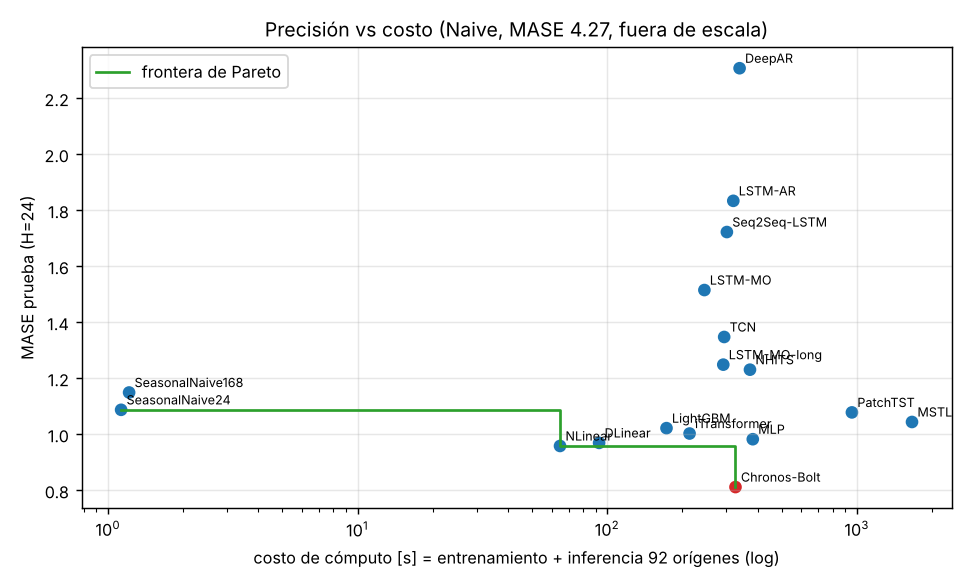

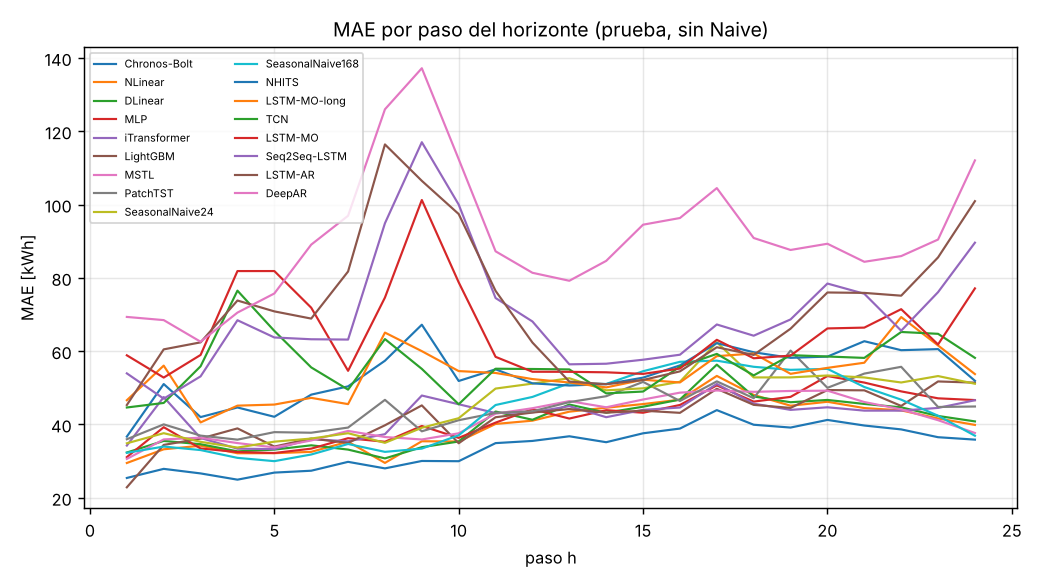

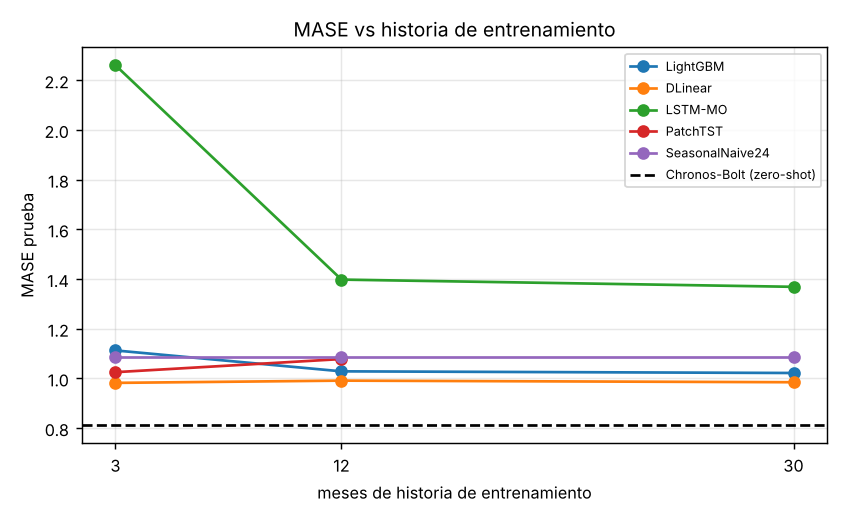

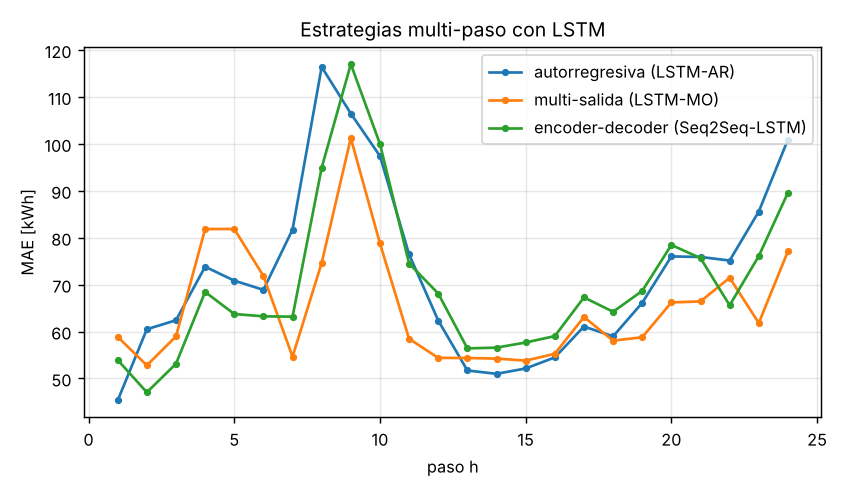

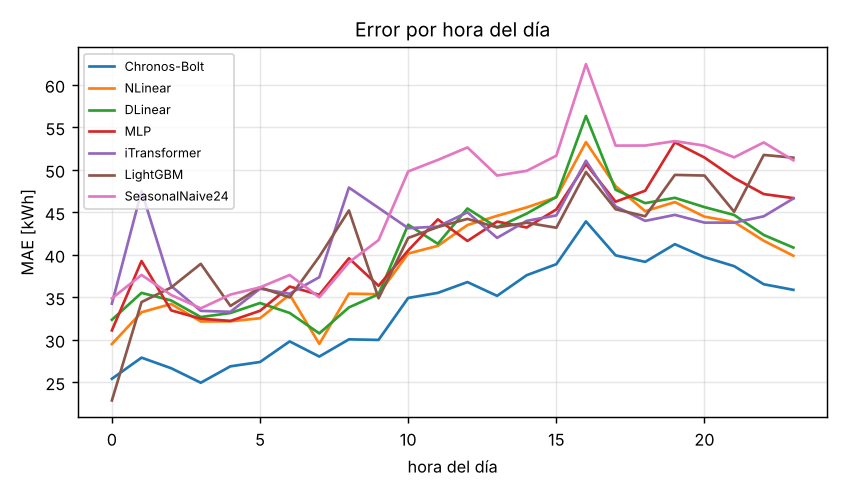

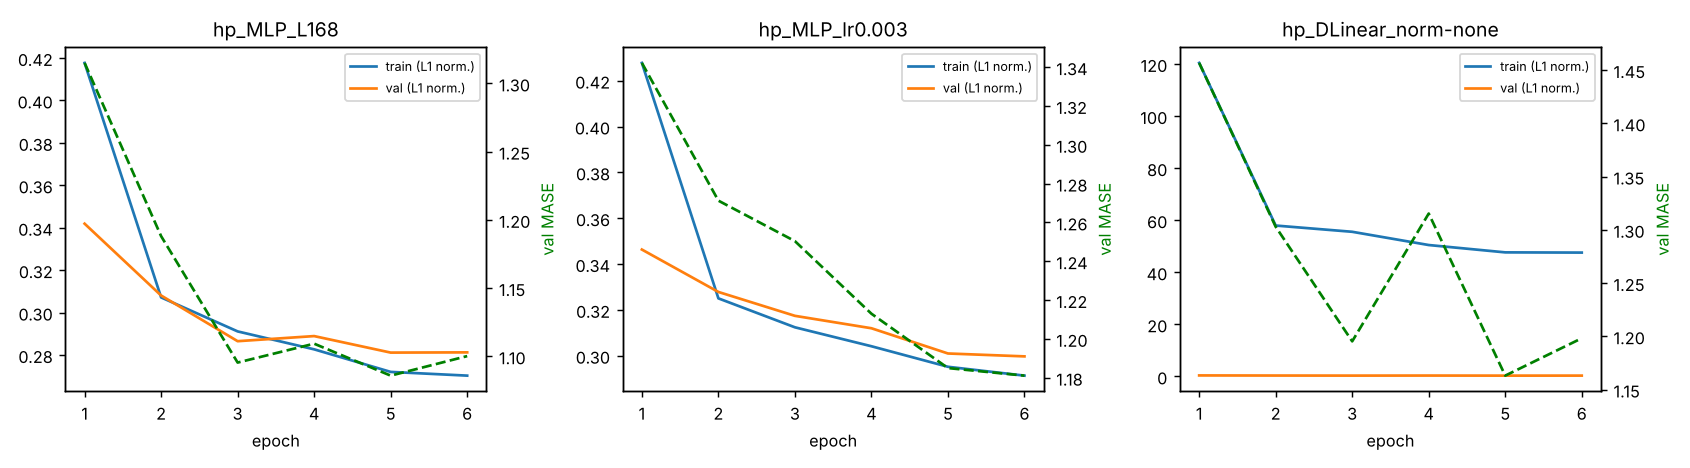

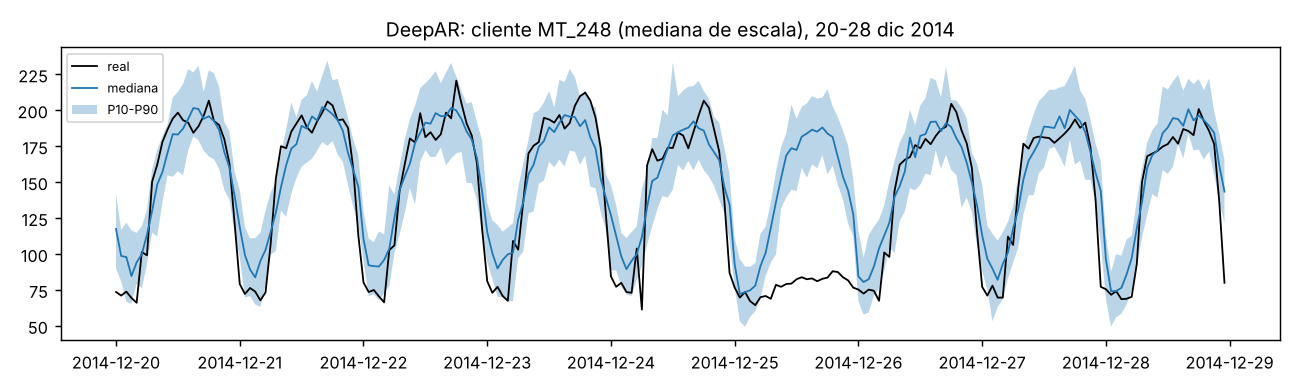

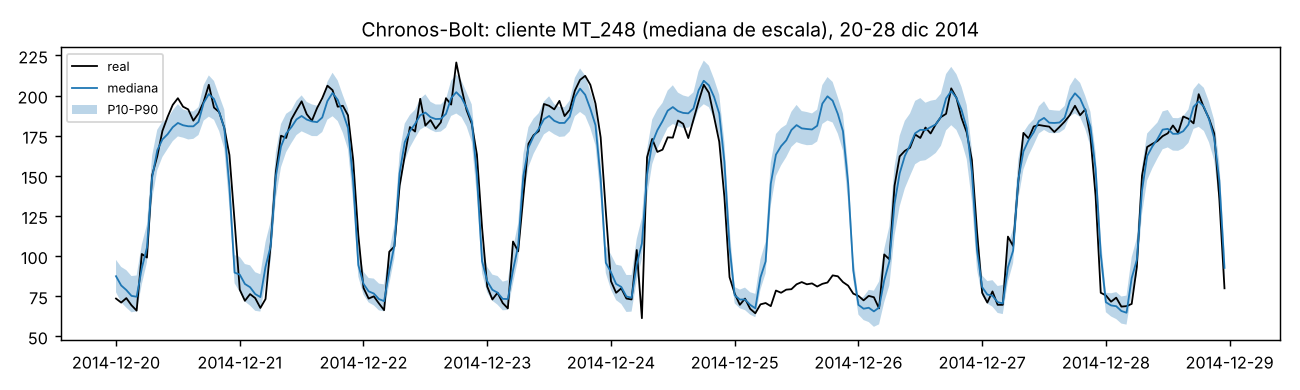

In [30]:
for f in ['pareto','mae_por_paso','mase_vs_historia','estrategias_lstm','mae_por_hora','curvas_perdida','bandas_DeepAR','bandas_Chronos-Bolt']:
    p=f'results/figures/{f}.png'
    if os.path.exists(p): display(Image(p))

### Tabla de iteraciones (selección por validación)

In [31]:
it = pd.read_csv('results/tabla_iteraciones.csv'); display(it)

,tag,arch,L,H,hist_months,norm,lr,batch,model_kw,epochs,params,train_s,epoch_s,infer_s,peak_mem_MB,val_MASE,test_MASE
0,hp_DLinear_L168,DLinear,168,24,30,series,0.003,256,{},6,8112,7.8,1.04,0.21,581,0.9105,0.9849
1,hp_DLinear_L336,DLinear,336,24,30,series,0.003,256,{},6,16176,9.6,1.25,0.36,610,0.9126,0.9718
2,hp_DLinear_L48,DLinear,48,24,30,series,0.003,256,{},6,2352,5.3,0.78,0.06,558,0.9834,1.0758
3,hp_DLinear_norm-global,DLinear,168,24,30,global,0.003,256,{},6,8112,7.5,1.02,0.25,654,1.8481,1.9248
4,hp_DLinear_norm-none,DLinear,168,24,30,none,0.003,256,{},6,8112,8.3,1.12,0.30,654,1.1631,1.1936
5,hp_DLinear_norm-revin,DLinear,168,24,30,revin,0.003,256,{},6,8114,10.1,1.32,0.27,655,0.9681,1.0532
6,hp_DLinear_norm-series,DLinear,168,24,30,series,0.003,256,{},6,8112,8.0,1.03,0.16,654,0.9105,0.9849
7,hp_MLP_L168,MLP,168,24,30,series,0.001,256,"{""hidden"": 512, ""layers"": 2, ""dropout"": 0.1}",6,1147928,23.8,3.21,0.64,610,1.0859,1.1101
8,hp_MLP_L336,MLP,336,24,30,series,0.001,256,"{""hidden"": 512, ""layers"": 2, ""dropout"": 0.1}",6,1922072,31.6,4.24,1.11,654,1.1229,1.1200
9,hp_MLP_L48,MLP,48,24,30,series,0.001,256,"{""hidden"": 512, ""layers"": 2, ""dropout"": 0.1}",6,594968,14.5,2.08,0.27,579,1.1193,1.1912


### Local vs global, semillas y reentrenamiento

In [32]:
for f in ['results/experiments/local_vs_global.csv','results/experiments/seeds.csv']:
    if os.path.exists(f): display(pd.read_csv(f).round(4))
for f in ['results/experiments/retrain_dl.json','results/experiments/best_own.json']:
    if os.path.exists(f): print(f, json.load(open(f)))

,unique_id,mean_kwh,MASE_local,MASE_global,local_train_s
0,MT_046,131.0938,0.8576,0.8593,2.3523
1,MT_051,54.6219,0.7771,0.7526,1.8434
2,MT_084,211.3382,0.8129,0.9695,2.4533
3,MT_187,57.3434,1.4756,1.4008,1.1998
4,MT_250,92.0258,0.9613,0.9268,2.3833
5,MT_274,322.4019,0.8763,0.8561,2.0256
6,MT_280,284.9817,1.1235,1.0737,2.5129
7,MT_318,168.2440,1.0743,0.8957,1.6057
8,MT_349,187.5346,0.9883,0.9607,2.6233
9,MT_360,512.0452,0.9447,0.8784,1.9260


,seed,val_MASE,MAE,RMSE,WAPE,MAPE,MASE,infer_s,MASE_xmas,MAE_xmas
0,0,0.8785,40.1014,192.1818,0.0743,11.6312,0.9592,0.0580,2.0381,93.8217
1,1,0.8776,40.2698,192.0938,0.0747,11.7140,0.9597,0.0561,2.0169,92.8552
2,2,0.8736,40.0280,191.6079,0.0742,11.7879,0.9594,0.0514,2.0278,92.8560


results/experiments/retrain_dl.json {'model': 'NLinear', 'monthly_refit': {'MAE': 40.299678802490234, 'RMSE': 193.88450622558594, 'WAPE': 0.07471604645252228, 'MAPE': 11.796308517456055, 'MASE': 0.9634101390838623}}
results/experiments/best_own.json {'name': 'NLinear', 'arch': 'NLinear', 'kw': {'L': 168, 'norm': 'series', 'lr': 0.003, 'batch_size': 256, 'epochs': 9, 'samples_per_epoch': 40000, 'patience': 3}, 'best_val_MASE': 0.874500036239624, 'best_epoch': 6}


## 8. Discusión y análisis (con base en los resultados de prueba)

**¿Qué modelo ganó?** **Chronos-Bolt-small zero-shot** obtuvo MASE **0.812** (MAE 33.8 kWh, WAPE 6.3%), un **25.4% mejor que el seasonal naive de 24 h** (MASE 1.088). Entre los modelos entrenados el mejor fue **NLinear (0.958, −11.9%)**, seguido de DLinear (0.969), MLP (0.983), iTransformer (1.003), LightGBM (1.022) y MSTL (1.044, el mejor baseline estadístico). NLinear entrena en ~1 min en CPU, tiene 4 k parámetros y predice los 92 orígenes en <1 s: en producción la mejora sí compensa su costo, porque reentrenarlo y mantenerlo es trivial. Chronos no requiere entrenamiento, pero la inferencia de los 92 orígenes costó ~5.4 min en CPU (frente a <1 s de NLinear) y depende de un modelo de 48 M parámetros. La frontera de Pareto (MASE vs costo total de entrenamiento + inferencia) queda formada por los seasonal naive, NLinear y Chronos.

**DLinear vs. Transformers.** Sí se replica: con H=24, DLinear (0.969) y NLinear (0.958) superan a los dos Transformers, iTransformer (1.003) y PatchTST (1.078), ambos entrenados con 12 meses y 150 pasos en CPU, y también a N-HiTS (1.231), TCN (1.348) y a los modelos recurrentes. Con H=168, DLinear (1.096) y NLinear (1.106) quedan cerca del seasonal naive semanal (SN168 ≈ 1.15–1.16) y muy por delante del MLP (1.384), cuya cantidad de parámetros crece con H. La ventaja de los lineales es robustez y bajo costo; los Transformers necesitarían bastante más cómputo para aprovechar su capacidad.

**Estrategias multi-paso (LSTM, mismo presupuesto).** La multi-salida fue la mejor (1.515), seguida del encoder–decoder (1.722) y la autorregresiva (1.834). La **acumulación de errores de la autorregresiva** es clara: su MAE pasa de 45 kWh en h=1 (la mejor de las tres, porque se entrena como modelo de un paso) a 101 kWh en h=24 (×2.2). La multi-salida pasa de 59 a 77 kWh (×1.3) y el seq2seq de 54 a 90. Por familias: el seasonal naive y los lineales tienen error casi plano en h (el paso coincide con la hora del día y su error sigue el perfil diario); LightGBM recursivo crece de 23 a 51 kWh; Chronos va de 25 a 36. Con más presupuesto (LSTM-MO-long, 12 epochs) la LSTM bajó a 1.249, todavía detrás de los lineales: en CPU las recurrentes quedan sub-entrenadas.

**Ventana L, normalización e historia** (selección por MASE de validación, tabla de iteraciones). *L:* en DLinear, L=48 da 0.983 en validación frente a 0.911 con L=168 y 0.913 con L=336. Hace falta ver al menos una semana para capturar el ciclo semanal, y duplicarla no aporta. El MLP prefiere L=168 (1.086). *Normalización:* es el factor más importante. En DLinear, z-score por serie (0.911) < RevIN (0.968) < sin normalizar (1.163) ≪ global (1.848). Con escalas de 8 a 11,000 kWh, la normalización global hace que los clientes grandes dominen la pérdida. En el MLP, sin normalizar da 1.491 y RevIN 1.331, frente a 1.086 por serie. *Historia:* DLinear casi no cambia con 3, 12 o 30 meses (0.982 / 0.991 / 0.985 en prueba), porque con 8 k parámetros 3 meses ya bastan. LightGBM sí mejora con más historia (1.113 → 1.029 → 1.022). La LSTM la necesita (3 m: 2.26 → 12 m: 1.40 → 30 m: 1.37) y PatchTST empeoró de 3 a 12 meses (1.025 → 1.078) con el mismo número de pasos: más datos con presupuesto fijo significa menos pasadas por ejemplo. En estos datos el deep learning lineal ya supera a LightGBM y al seasonal naive **desde 3 meses**; los modelos recurrentes no lo logran ni con 30 meses bajo este presupuesto. *Otros (MLP):* 1 capa (0.985) fue mejor que 2 (1.086); más dropout (0.3: 1.205), lr 3e-3 (1.181), oculto 128 (1.096) y batch 1024 (1.144) empeoraron. *¿Una pérdida de entrenamiento más baja implica mejor MASE de validación?* No siempre: en las curvas, la pérdida de entrenamiento baja de forma monótona mientras el MASE de validación oscila, y el MLP de 2 capas tiene menor pérdida de entrenamiento que el de 1 capa pero peor validación (sobreajuste). Por eso el early stopping se hace con el MASE de validación.

**Local vs. global** (NLinear, 10 clientes elegidos con semilla). El global gana en promedio: MASE 0.957 frente a 0.989 local, y es mejor en 8 de 10 clientes. Los que más se benefician (MT_318: −0.18; MT_187: −0.07) tienen perfiles irregulares, donde compartir patrones de calendario entre series regulariza. Solo MT_084 mejora con su modelo propio (−0.16), lo que sugiere un patrón idiosincrático. Además, un modelo global se entrena una vez, en lugar de 10 o 100.

**Chronos zero-shot.** Fue el mejor en MASE, MAE y WAPE sin ver ningún dato de entrenamiento, y su intervalo P10–P90 cubre el **80.4%** (nominal 80%) con pinball 11.7 kWh. Lo usaría cuando hay poca historia, series nuevas (*cold start*), muchos clientes heterogéneos o no hay tiempo ni infraestructura para entrenar. Entrenaría una red ligera (NLinear) cuando la latencia o el costo de inferencia importan, o cuando hay covariables que Chronos-Bolt no usa (feriados).

**Pronóstico probabilístico.** Chronos-Bolt (pinball medio 11.7 kWh, cobertura P10–P90 de 80.4%) está prácticamente calibrado. DeepAR, con solo 150 pasos y 6 meses de historia en CPU, quedó sub-entrenado: MASE 2.307, pinball 31.2 kWh y cobertura de 55.7%. Sus intervalos son demasiado estrechos respecto a su error.

**Navidad y Año Nuevo** (22–28 dic). Todos los modelos empeoran: el MASE sube a 1.6–2.6. Los mejores esa semana fueron Chronos (1.597), SN168 (1.667) y el MLP (1.704); NLinear y DLinear suben a ~2.0–2.04, y LightGBM, que tiene la covariable de feriado, a 1.934. Solo hay un feriado en la semana y es irrepetible en entrenamiento (2 ocurrencias en 30 meses), así que la covariable apenas ayuda. Los modelos que usan la semana previa (SN168) o mucho contexto (Chronos, MLP) degradan menos. Es un cambio de régimen que afecta a todos.

**Semillas.** NLinear con semillas 0, 1 y 2 dio MASE de prueba 0.9592 / 0.9597 / 0.9594, con **σ = 0.00025**: el modelo lineal es prácticamente determinista. Las diferencias de ~0.01 entre modelos lineales son mayores que la varianza por semilla.

**Reentrenamiento mensual** (ventana expandible, 1-oct / 1-nov / 1-dic, epochs fijos = mejor epoch de validación). NLinear pasa de 0.9585 (entrenado una vez) a 0.9634: **no mejora**. Tres meses adicionales sobre 30 de historia no cambian un modelo lineal. Para el mejor baseline (**MSTL**, MASE 1.044) el reentrenamiento mensual es idéntico por construcción: es un modelo local que ya se reajusta en cada origen diario con la historia previa (una versión más agresiva del reentrenamiento), así que su error no cambia.

**Limitaciones.** Todo corrió en una CPU de 2 núcleos y sin GPU, con 100 clientes. Los modelos pesados (LSTM, Transformers, DeepAR) tuvieron presupuestos reducidos, y los de NeuralForecast se entrenaron con 12 meses de historia por memoria (TCN y DeepAR con 6 meses, tras dos cierres por falta de memoria). Sus resultados son cotas inferiores de lo que lograrían en GPU. MSTL se ajustó con una ventana de 2 semanas por origen debido a su costo (~20–35 s por origen).


## Entregables
- `predicciones_test.csv.gz` (`unique_id, ds, modelo, y_hat`) en `results/`.
- Reporte PDF en `reporte/`.
- `requirements.txt` y `README.md` para reproducir.